#  Анализ данных e-commerce онлайн магазина-агрегатора Olist Store

---

##  Описание проекта
В данном ноутбуке проводится анализ данных (EDA) e-commerce бразильского онлайн магазина Olist Store.  [Датасет](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce/data) содержит данные о 100 тысячах заказов, сделанных с 2016 по 2018 год в разных бразильских маркетплейсах. Изучается структура заказов, поведение клиентов, финансовые показатели, выявляются ключевые статистические закономерности. Также анализируется датасет дополнение к основному датасету [Marketing Funnel by Olist](https://www.kaggle.com/datasets/olistbr/marketing-funnel-olist).

Olist - это крупнейшая платформа агрегатор для малого бизнеса в Бразилии, позволяющая начать продажи сразу на разных маркетплейсах. Малый бизнес может заключить контракт с Olist и получить доступ сразу к разным маркетплейсам (Amazon, Mercado Livre) и к логистической службе Olist и партнеров. Также компания Olist берет на себя юридические и налоговые вопросы.

В датасете представлены реальные коммерческие анонимизированные данные, а упоминания других маркетплейсов и продавцов были заменены на названия великих домов из Игры Престолов.


##  Схема данных
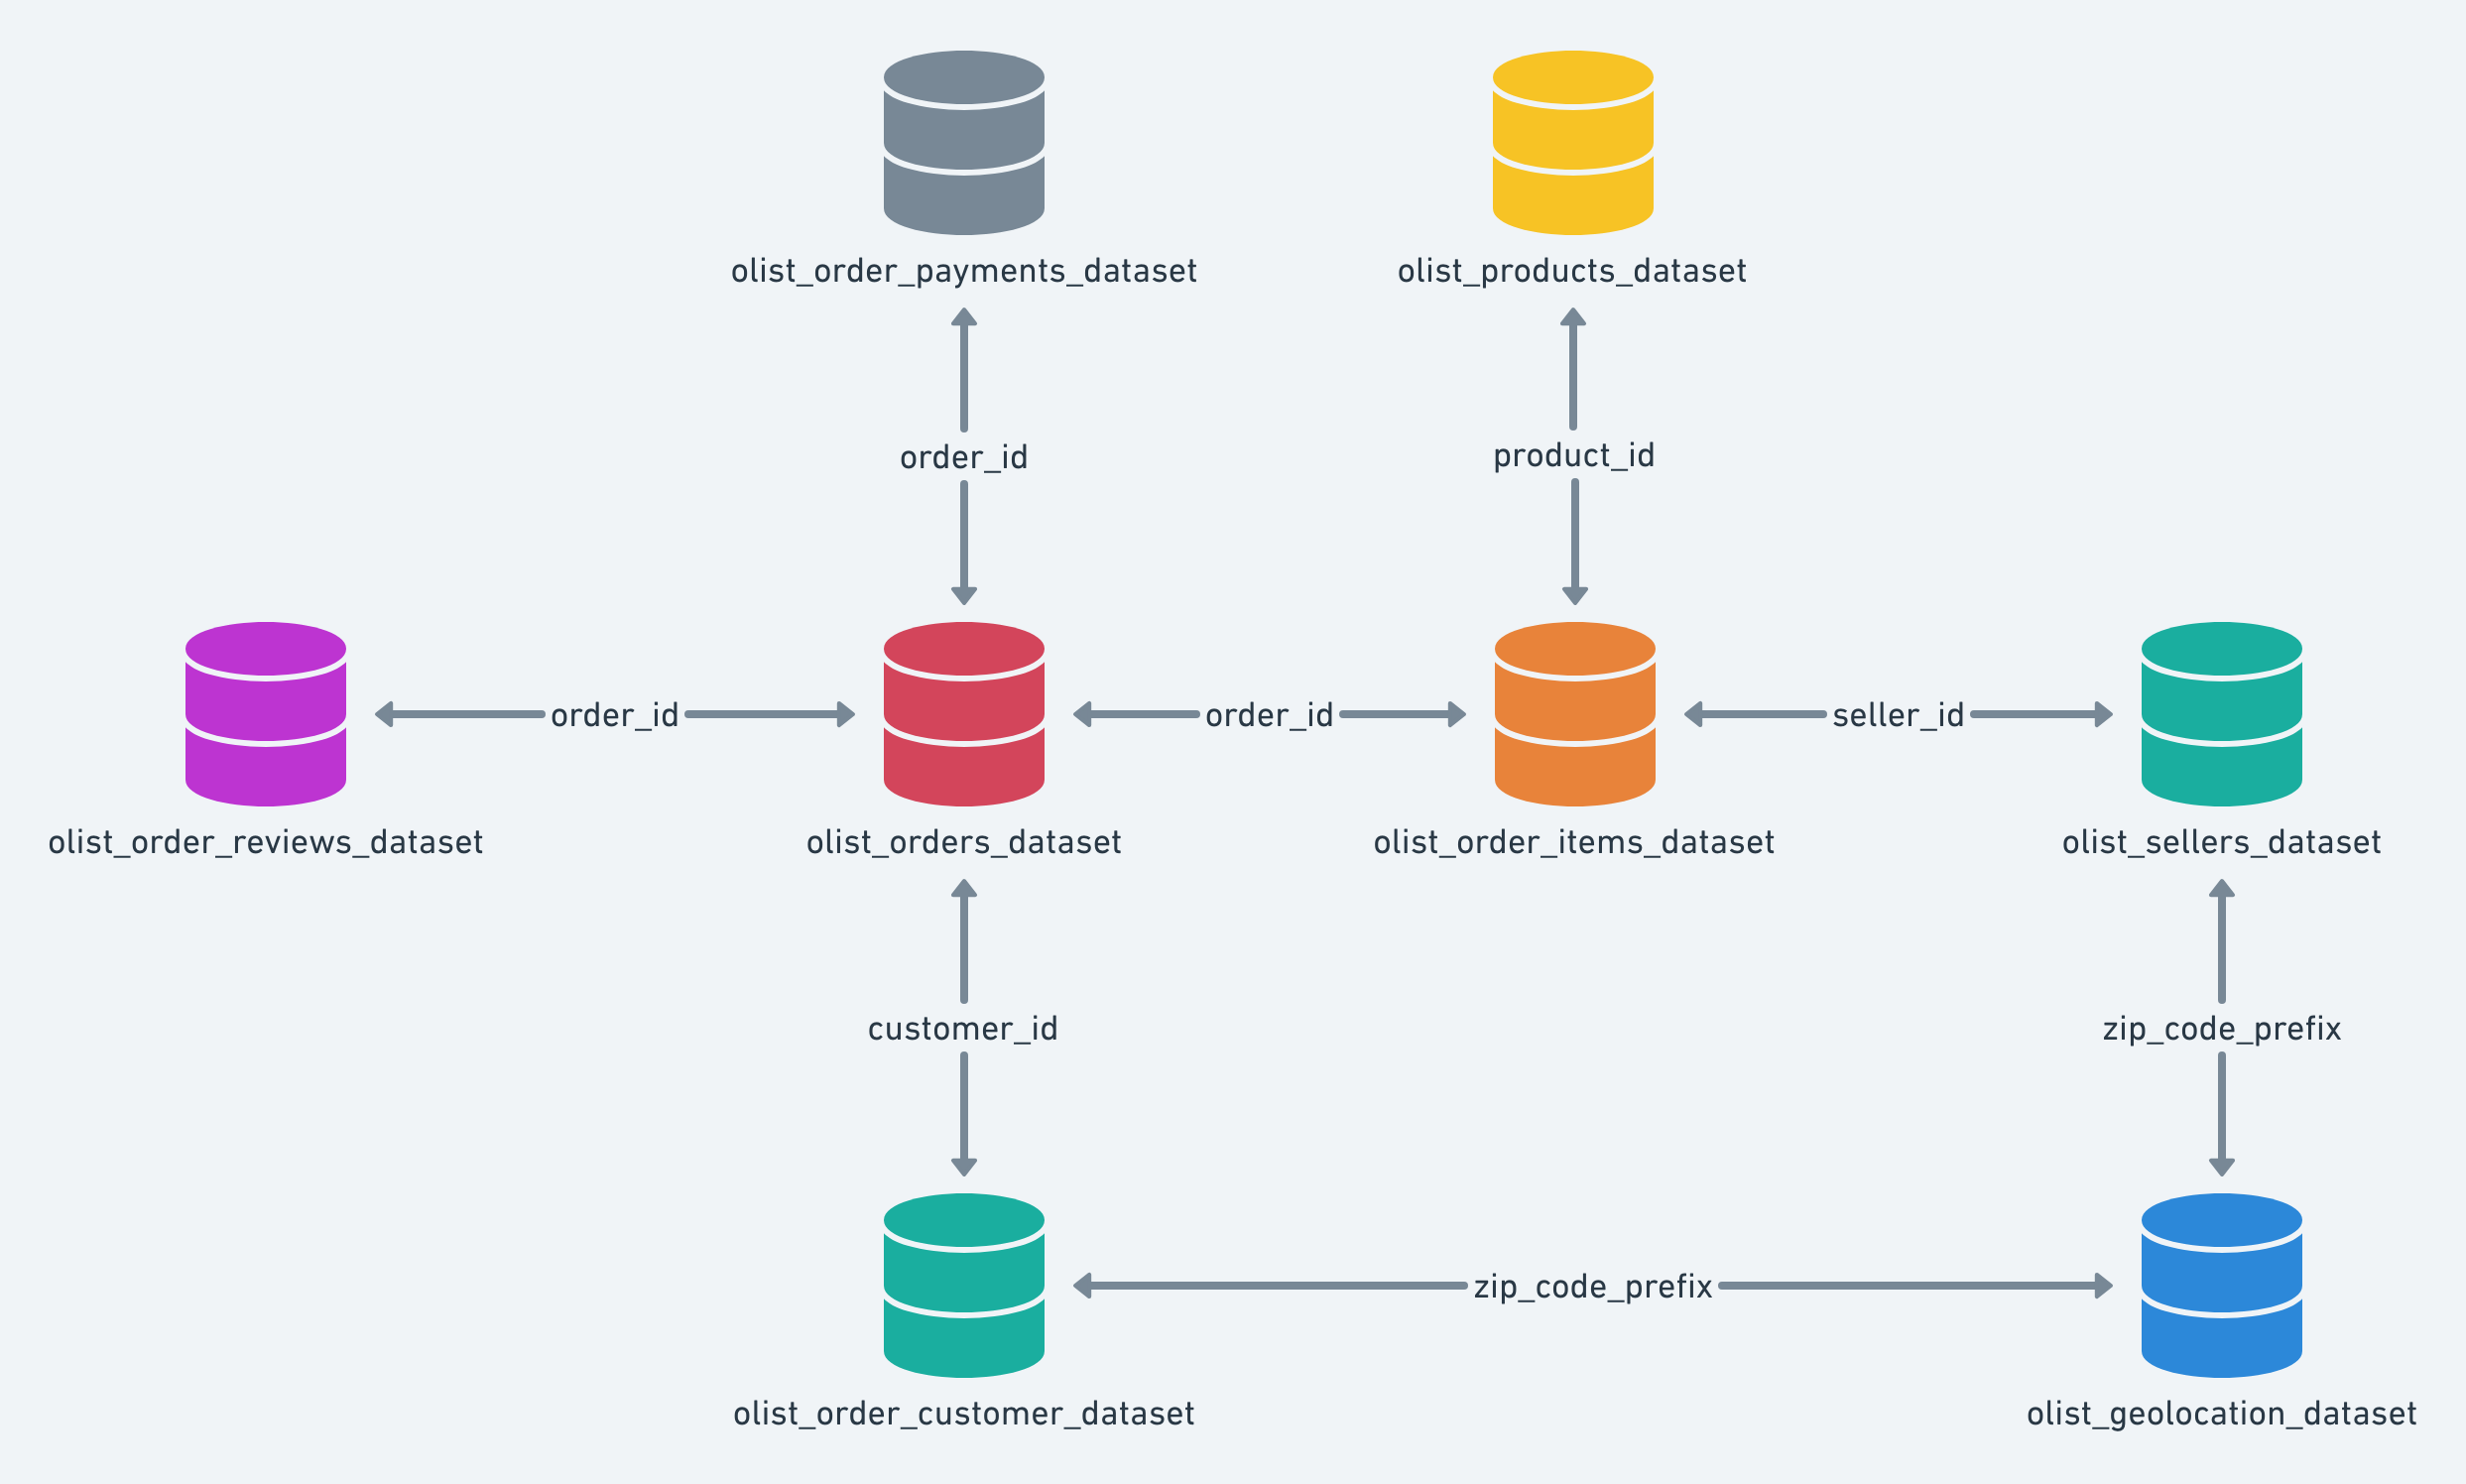

##  Основные этапы анализа:
1. [Загрузка и предобработка данных](#scrollTo=z_5o8SlXf6kg&line=18&uniqifier=1)
2. [Анализ экономики и пользователей платформы](#scrollTo=4ud0hOsktoCv&line=4&uniqifier=1)
Визуализация и анализ распределений количественных и категориальных данных (стоимости заказов, времени и стоимости доставки, пользовательских оценок, статусов заказов, способов оплаты/ месяцев отсрочки, категорий товаров и другое)
3. [Расчет продуктовых метрик](#scrollTo=ZsyowZtZqahv&line=1&uniqifier=1)
GMV, выручки, ARPPU, MAU,  Retention Rate, частоты покупок, RFM-сегментов, индекса лояльности NPS
4. [Анализ Marketing Funnel датасета](#scrollTo=95QZitewHhmi&uniqifier=1)
5. [Статистический анализ](#scrollTo=FEdTe97kHKy3&uniqifier=1)
проверка гипотез: увеличение медианы и других процентилей ARPPU между 2017 и 2018 годами, уменьшение для времени доставки, увеличение MAU,  связь между регионом и типом оплаты, связь между типом отзыва и категорией товара, связь между количеством дней задержки и оценкой заказа


## Описание колонок всех датасетов:
### `orders`
*   **`order_id`**: Уникальный идентификатор каждого заказа.
*   **`customer_id`**: Уникальный идентификатор клиента.
*   **`order_status`**: Текущий статус заказа (например, 'delivered' — доставлен, 'shipped' — отправлен, 'canceled' — отменен).
*   **`order_purchase_timestamp`**: Временная метка момента совершения покупки.
*   **`order_approved_at`**: Временная метка подтверждения оплаты заказа.
*   **`order_delivered_carrier_date`**: Временная метка передачи заказа логистическому партнеру (перевозчику).
*   **`order_delivered_customer_date`**: Фактическая дата доставки заказа клиенту.
*   **`order_estimated_delivery_date`**: Планируемая дата доставки, которая была сообщена клиенту в момент покупки.
### `customers`
*   **`customer_id`**: Уникальный ключ клиента для каждого конкретного заказа (связывает клиента с таблицей `orders`).
*   **`customer_unique_id`**: Постоянный уникальный идентификатор самого покупателя. Позволяет отслеживать повторные покупки одного и того же человека.
*   **`customer_zip_code_prefix`**: Первые пять цифр почтового индекса покупателя.
*   **`customer_city`**: Название города, в котором проживает покупатель.
*   **`customer_state`**: Код штата проживания покупателя (например, SP, RJ).

### `order_items`
*   **`order_id`**: Идентификатор заказа, к которому относится товар.
*   **`order_item_id`**: Порядковый номер товара внутри одного чека (например, если в заказе 3 товара, значения будут 1, 2, 3).
*   **`product_id`**: Уникальный идентификатор самого товара.
*   **`seller_id`**: Уникальный идентификатор продавца, чей товар был куплен.
*   **`shipping_limit_date`**: Крайний срок, установленный Olist, до которого продавец обязан передать товар логистической компании.
*   **`price`**: Стоимость самого товара (за одну единицу).
*   **`freight_value`**: Стоимость доставки этого товара (если в заказе несколько позиций, общая стоимость доставки распределяется между ними).

### `order_payments`
*   **`order_id`**: Уникальный идентификатор заказа.
*   **`payment_sequential`**: Порядковый номер платежа. Покупатель может оплатить один заказ несколькими способами (например, часть бонусами, часть картой).
*   **`payment_type`**: Способ оплаты (например, 'credit_card' — кредитная карта, 'boleto' — банковский билет, 'voucher' — ваучер/бонусы, 'debit_card' — дебетовая карта).
*   **`payment_installments`**: Количество выбранных покупателем долей/месяцев для рассрочки платежа (очень популярно в Бразилии).
*   **`payment_value`**: Общая сумма, уплаченная данным способом в рамках этого транша.

### `order_reviews`
*   **`review_id`**: Уникальный идентификатор отзыва.
*   **`order_id`**: Уникальный идентификатор заказа, на который оставлен отзыв.
*   **`review_score`**: Оценка товара/сервиса покупателем по шкале от 1 до 5 звезд (ключевая метрика качества).
*   **`review_comment_title`**: Заголовок текстового отзыва (может быть пустым).
*   **`review_comment_message`**: Сам текст отзыва покупателя (может быть пустым).
*   **`review_creation_date`**: Дата, когда покупателю была отправлена анкета для заполнения отзыва.
*   **`review_answer_timestamp`**: Точная временная метка, когда покупатель отправил заполненный отзыв.

### `products`
*   **`product_id`**: Уникальный идентификатор товара.
*   **`product_category_name`**: Название категории товара на португальском языке.
*   **`product_name_lenght`**: Количество символов в названии товара.
*   **`product_description_lenght`**: Количество символов в описании товара.
*   **`product_photos_qty`**: Количество фотографий товара в карточке.
*   **`product_weight_g`**: Вес товара в граммах.
*   **`product_length_cm`**: Длина товара в сантиметрах.
*   **`product_height_cm`**: Высота товара в сантиметрах.
*   **`product_width_cm`**: Ширина товара в сантиметрах.

### `sellers`
*   **`seller_id`**: Уникальный идентификатор продавца.
*   **`seller_zip_code_prefix`**: Первые пять цифр почтового индекса продавца.
*   **`seller_city`**: Город, в котором зарегистрирован или находится склад продавца.
*   **`seller_state`**: Штат, в котором находится продавец.

### `geolocation`
*   **`geolocation_zip_code_prefix`**: Первые пять цифр почтового индекса.
*   **`geolocation_lat`**: Широта географической точки.
*   **`geolocation_lng`**: Долгота географической точки.
*   **`geolocation_city`**: Название города, привязанного к этому индексу.
*   **`geolocation_state`**: Название штата.

### `product_category_name_translation`
*   **`product_category_name`**: Название категории товара на португальском языке (для связи с таблицей `products`).
*   **`product_category_name_english`**: Перевод названия категории на английский язык.

# Загрузка и предобработка данных

In [ ]:
import kagglehub
import shutil
import os

# 1. Скачивание последней версии датасета через kagglehub
print("Загрузка датасета...")
path_hub = kagglehub.dataset_download("olistbr/brazilian-ecommerce")

# 2. Перемещение файлов в нашу рабочую папку e-commerce_olist
dest_path = '/content/e-commerce_olist'

if not os.path.exists(dest_path):
    os.makedirs(dest_path)

# 3. Копируем содержимое из кэша kagglehub в нашу папку
for filename in os.listdir(path_hub):
    shutil.copy(os.path.join(path_hub, filename), os.path.join(dest_path, filename))

print(f"\nДанные успешно загружены через kagglehub и скопированы в: {dest_path}")
!ls {dest_path}

Загрузка датасета...
Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.

Данные успешно загружены через kagglehub и скопированы в: /content/e-commerce_olist
olist_customers_dataset.csv	  olist_orders_dataset.csv
olist_geolocation_dataset.csv	  olist_products_dataset.csv
olist_order_items_dataset.csv	  olist_sellers_dataset.csv
olist_order_payments_dataset.csv  product_category_name_translation.csv
olist_order_reviews_dataset.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Путь к папке с данными
data_path = '/content/e-commerce_olist'

# Load datasets with '_raw' suffix
customers_raw = pd.read_csv(os.path.join(data_path, 'olist_customers_dataset.csv'))
orders_raw = pd.read_csv(os.path.join(data_path, 'olist_orders_dataset.csv'))
items_raw = pd.read_csv(os.path.join(data_path, 'olist_order_items_dataset.csv'))
products_raw = pd.read_csv(os.path.join(data_path, 'olist_products_dataset.csv'))
payments_raw = pd.read_csv(os.path.join(data_path, 'olist_order_payments_dataset.csv'))
reviews_raw = pd.read_csv(os.path.join(data_path, 'olist_order_reviews_dataset.csv'))
geolocation_raw = pd.read_csv(os.path.join(data_path, 'olist_geolocation_dataset.csv'))
sellers_raw = pd.read_csv(os.path.join(data_path, 'olist_sellers_dataset.csv'))
category_translation_raw = pd.read_csv(os.path.join(data_path, 'product_category_name_translation.csv'))



In [ ]:
customers = customers_raw.copy()
orders = orders_raw.copy()
items = items_raw.copy()
products = products_raw.copy()
payments = payments_raw.copy()
reviews = reviews_raw.copy()
geolocation = geolocation_raw.copy()
sellers = sellers_raw.copy()
category_translation = category_translation_raw.copy()

In [ ]:
datasets = {
    "orders": orders,
    "customers": customers,
    "geolocation": geolocation,
    "items": items,
    "payments": payments,
    "reviews": reviews,
    "products": products,
    "sellers": sellers,
    "category_translation": category_translation
}

In [ ]:
for name, df in datasets.items():
    print(
        f"{name:<20} | "
        f"rows: {df.shape[0]:>7} | "
        f"cols: {df.shape[1]:>2} | "
        f"missing: {df.isnull().sum().sum():>6} | "
        f"duplicates: {df.duplicated().sum():>6}"
    )

orders               | rows:   99441 | cols:  8 | missing:   4908 | duplicates:      0
customers            | rows:   99441 | cols:  5 | missing:      0 | duplicates:      0
geolocation          | rows: 1000163 | cols:  5 | missing:      0 | duplicates: 261831
items                | rows:  112650 | cols:  7 | missing:      0 | duplicates:      0
payments             | rows:  103886 | cols:  5 | missing:      0 | duplicates:      0
reviews              | rows:   99224 | cols:  7 | missing: 145903 | duplicates:      0
products             | rows:   32951 | cols:  9 | missing:   2448 | duplicates:      0
sellers              | rows:    3095 | cols:  4 | missing:      0 | duplicates:      0
category_translation | rows:      71 | cols:  2 | missing:      0 | duplicates:      0


In [ ]:
column_analytics = []

for dataset_name, df in datasets.items():
    for col in df.columns:

        col_data = df[col]

        column_analytics.append({
            "Dataset": dataset_name,
            "Column Name": col,
            "Data Type": str(col_data.dtype),
            "Length": len(col_data),
            "Null Count": col_data.isnull().sum(),
            "Missing %": round(col_data.isnull().sum() / len(df) * 100, 1),
            "Unique Values": col_data.nunique(),
            "Zeros": (col_data == 0).sum() if pd.api.types.is_numeric_dtype(col_data) else 0,
            # Считаем пустые строки (удаляя пробелы `.str.strip()`, если тип данных текстовый)
            "Empty Strings": col_data.astype(str).str.strip().eq('').sum() if str(col_data.dtype) == 'object' else 0
        })


df_all_columns = pd.DataFrame(column_analytics)


pd.set_option('display.max_rows', 10)


df_all_columns

,Dataset,Column Name,Data Type,Length,Null Count,Missing %,Unique Values,Zeros,Empty Strings
0,orders,order_id,object,99441,0,0.0,99441,0,0
1,orders,customer_id,object,99441,0,0.0,99441,0,0
2,orders,order_status,object,99441,0,0.0,8,0,0
3,orders,order_purchase_timestamp,object,99441,0,0.0,98875,0,0
4,orders,order_approved_at,object,99441,160,0.2,90733,0,0
...,...,...,...,...,...,...,...,...,...
47,sellers,seller_zip_code_prefix,int64,3095,0,0.0,2246,0,0
48,sellers,seller_city,object,3095,0,0.0,611,0,0
49,sellers,seller_state,object,3095,0,0.0,23,0,0
50,category_translation,product_category_name,object,71,0,0.0,71,0,0


### Проверка цепочки пропусков в данных

Проверим, являются ли 160 заказов без даты подтверждения (`order_approved_at`) также пропусками в последующих этапах (доставка).

In [ ]:
# Выделяем заказы, где order_approved_at является null
null_approved = orders[orders['order_approved_at'].isnull()]

# Проверяем количество пропусков в этих строках для других колонок дат
print("Количество пропусков в заказах, где order_approved_at = NaN:")
display(null_approved[['order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date']].isnull().sum())

Количество пропусков в заказах, где order_approved_at = NaN:


,0
order_approved_at,160
order_delivered_carrier_date,146
order_delivered_customer_date,146


### Поиск аномалий: статус 'delivered' с пустыми датами

Найдем строки, где заказ считается доставленным, но при этом отсутствует информация о времени подтверждения, отгрузки или фактического получения.

In [ ]:
# Список колонок с временными метками для проверки
time_columns = ['order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date']

# Фильтруем: статус 'delivered' И (хотя бы один из таймстампов равен null)
delivered_with_nulls = orders[
    (orders['order_status'] == 'delivered') &
    (orders[time_columns].isnull().any(axis=1))
]

print(f"Найдено заказов со статусом 'delivered' и пропуском в датах: {len(delivered_with_nulls)}")

Найдено заказов со статусом 'delivered' и пропуском в датах: 23


In [ ]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [ ]:
items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [ ]:
orders.order_status.unique()

array(['delivered', 'invoiced', 'shipped', 'processing', 'unavailable',
       'canceled', 'created', 'approved'], dtype=object)

In [ ]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [ ]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [ ]:
orders.isna().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [ ]:
orders.order_status.value_counts()

,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


# Анализ экономики и пользователей платформы

Провизуализируем доступные нам переменные, сначала числовые потом категориальные, посмотрим на распределение каждой переменной чтобы понять продукт и пользователей

### Стоимость покупки, цена товара, цена доставки, количество месяцев отсрочки, оценка товара покупателем, время доставки

In [ ]:
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xaxis.labellocation"] = "right"
plt.rcParams["yaxis.labellocation"] = "top"
plt.rcParams["axes.labelsize"] = 15
plt.rcParams["axes.labelpad"] = 10

In [ ]:
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xaxis.labellocation"] = "right"
plt.rcParams["yaxis.labellocation"] = "top"
plt.rcParams["axes.labelsize"] = 15
plt.rcParams["axes.labelpad"] = 10

In [ ]:
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#E6E6E6"
plt.rcParams["grid.linestyle"] = "--"
plt.rcParams["grid.linewidth"] = 0.8
plt.rcParams["axes.axisbelow"] = True


plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["xtick.color"] = "#4A4A4A"
plt.rcParams["ytick.color"] = "#4A4A4A"
plt.rcParams["xtick.labelsize"] = 11
plt.rcParams["ytick.labelsize"] = 11


plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]

sns.set_palette("muted")


In [ ]:
delivered_orders = orders[orders['order_status'] == 'delivered'].copy()
delivered_orders['order_purchase_timestamp'] = pd.to_datetime(delivered_orders['order_purchase_timestamp'])
delivered_orders['month'] = delivered_orders['order_purchase_timestamp'].dt.strftime('%Y-%m')
delivered_orders = delivered_orders.sort_values('month')

In [ ]:
payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [ ]:
payments.payment_type.value_counts()

,count
payment_type,
credit_card,76795
boleto,19784
voucher,5775
debit_card,1529
not_defined,3


Text(0.5, 1.0, 'Распредление стоимости заказов')

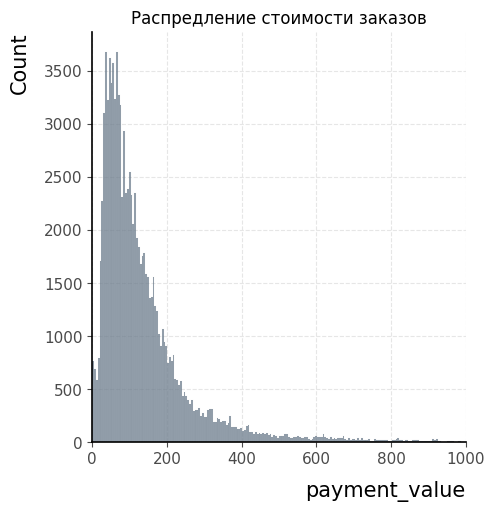

In [ ]:
sns.displot(data = payments, x='payment_value', color='slategrey')
plt.xlim(left = 0, right=1000)
plt.title("Распредление стоимости заказов")

In [ ]:
payments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [ ]:
payments.groupby('order_id', as_index=False)['payment_value'].sum()

,order_id,payment_value
0,00010242fe8c5a6d1ba2dd792cb16214,72.19
1,00018f77f2f0320c557190d7a144bdd3,259.83
2,000229ec398224ef6ca0657da4fc703e,216.87
3,00024acbcdf0a6daa1e931b038114c75,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04
...,...,...
99435,fffc94f6ce00a00581880bf54a75a037,343.40
99436,fffcd46ef2263f404302a634eb57f7eb,386.53
99437,fffce4705a9662cd70adb13d4a31832d,116.85
99438,fffe18544ffabc95dfada21779c9644f,64.71


In [ ]:
payments_grouped_to_orders = payments.groupby('order_id', as_index=False)['payment_value'].sum()
thr = payments_grouped_to_orders['payment_value'].quantile(0.95)
under_95_percentile_payments = payments_grouped_to_orders[payments_grouped_to_orders['payment_value'] < thr]

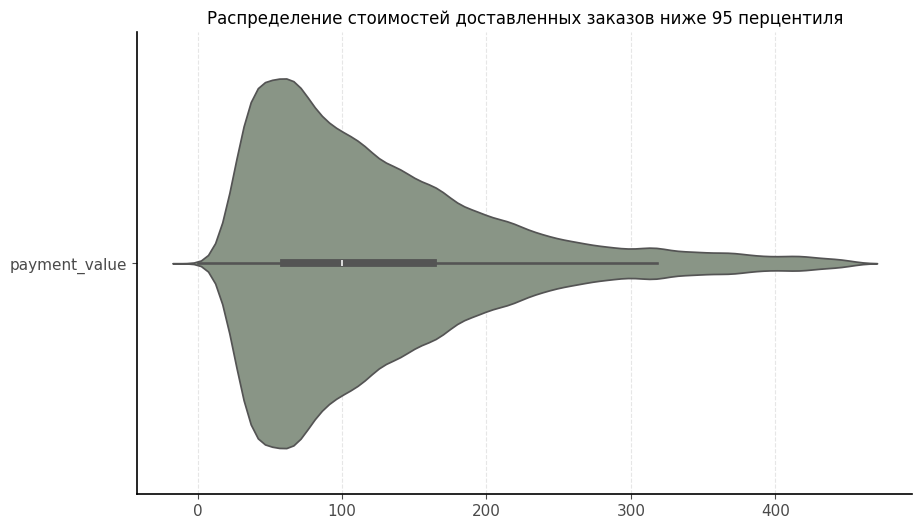

In [ ]:
fig = plt.figure(figsize=(10, 6))
sns.violinplot(data=under_95_percentile_payments, color='#879883', orient='h')
plt.title("Распределение стоимостей доставленных заказов ниже 95 перцентиля")
plt.show()

In [ ]:
payments

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45
...,...,...,...,...,...
103881,0406037ad97740d563a178ecc7a2075c,1,boleto,1,363.31
103882,7b905861d7c825891d6347454ea7863f,1,credit_card,2,96.80
103883,32609bbb3dd69b3c066a6860554a77bf,1,credit_card,1,47.77
103884,b8b61059626efa996a60be9bb9320e10,1,credit_card,5,369.54


In [ ]:
payments.groupby("order_id", as_index=False)["payment_installments"].max()

,order_id,payment_installments
0,00010242fe8c5a6d1ba2dd792cb16214,2
1,00018f77f2f0320c557190d7a144bdd3,3
2,000229ec398224ef6ca0657da4fc703e,5
3,00024acbcdf0a6daa1e931b038114c75,2
4,00042b26cf59d7ce69dfabb4e55b4fd9,3
...,...,...
99435,fffc94f6ce00a00581880bf54a75a037,1
99436,fffcd46ef2263f404302a634eb57f7eb,1
99437,fffce4705a9662cd70adb13d4a31832d,3
99438,fffe18544ffabc95dfada21779c9644f,3


Text(0.5, 1.0, 'Распределение числа платежей')

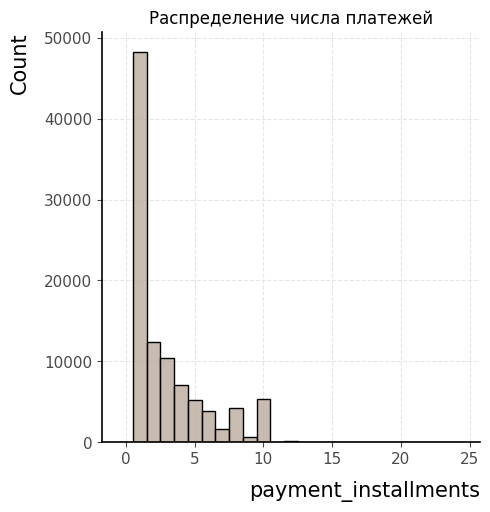

In [ ]:
sns.displot(data=payments.groupby("order_id", as_index=False)["payment_installments"].max(), x="payment_installments", color='#B5A695', discrete=True)
plt.title("Распределение числа платежей")

### Статус выполнения заказа, категория товара, способ оплаты, название города, название штата

In [ ]:
orders.order_status.value_counts()

,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [ ]:
status_order = orders['order_status'].value_counts().index

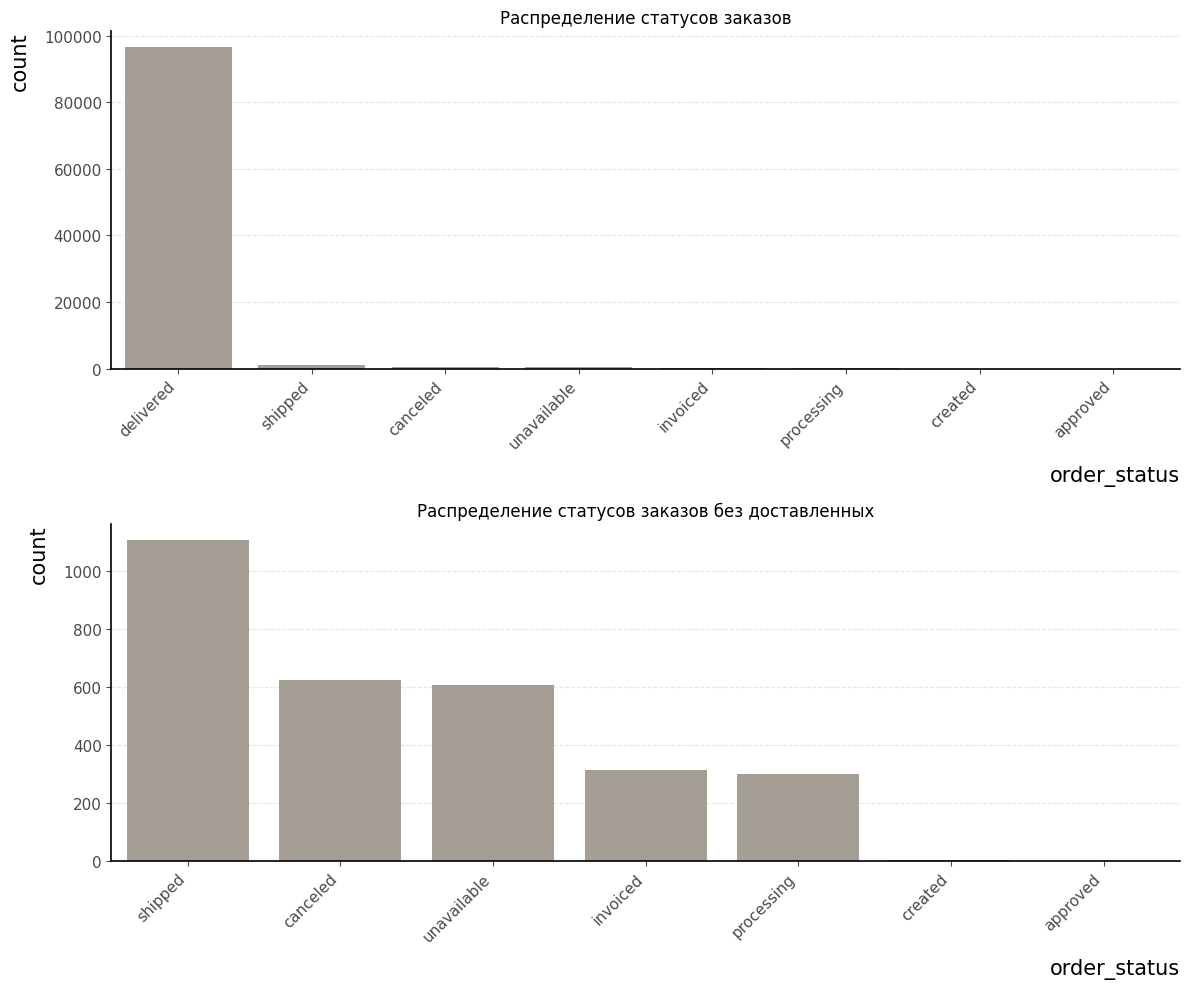

In [ ]:
plt.figure(figsize=(12, 10))
plt.subplot(2, 1, 1)
sns.countplot(data=orders, x='order_status', order=status_order, color="#A89F91")
plt.title("Распределение статусов заказов")
plt.xticks(rotation=45, ha='right')

plt.subplot(2, 1, 2)
orders_without_delivered = orders[orders['order_status'] != 'delivered']
status_order_filtered = [status for status in status_order if status != 'delivered']
sns.countplot(
    data=orders_without_delivered,
    x='order_status',
    order=status_order_filtered,
    color="#A89F91"
)
plt.title("Распределение статусов заказов без доставленных")
plt.xticks(rotation=45, ha='right')


plt.tight_layout()
plt.show()

In [ ]:
category_translation.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [ ]:
category_translation.shape

(71, 2)

In [ ]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [ ]:
delivered_orders_items = pd.merge(left=items, right=delivered_orders, how="left", on="order_id")

In [ ]:
delivered_orders_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,month
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29 00:00:00,2017-09
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15 00:00:00,2017-04
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05 00:00:00,2018-01
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20 00:00:00,2018-08
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17 00:00:00,2017-02


In [ ]:
delivered_items_with_product_categories = pd.merge(left=delivered_orders_items, right=products, on='product_id', how='left')
delivered_items_with_product_categories_translated = pd.merge(left=delivered_items_with_product_categories, right=category_translation, on='product_category_name', how='left')
# Если английского перевода нет, оставляем португальское название
df = delivered_items_with_product_categories_translated # для краткости кода
df['product_category_name_english'] = df['product_category_name_english'].fillna(df['product_category_name'])

# Если у товара вообще не была указана категория, заменим NaN на "unknown"
df['product_category_name_english'] = df['product_category_name_english'].fillna('unknown')


In [ ]:
top_categories = df.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False).head(15)
print(top_categories)

product_category_name_english
health_beauty            1258681.34
watches_gifts            1205005.68
bed_bath_table           1036988.68
sports_leisure            988048.97
computers_accessories     911954.32
                            ...    
toys                      483946.60
baby                      411764.89
perfumery                 399124.87
telephony                 323667.53
office_furniture          273960.70
Name: price, Length: 15, dtype: float64


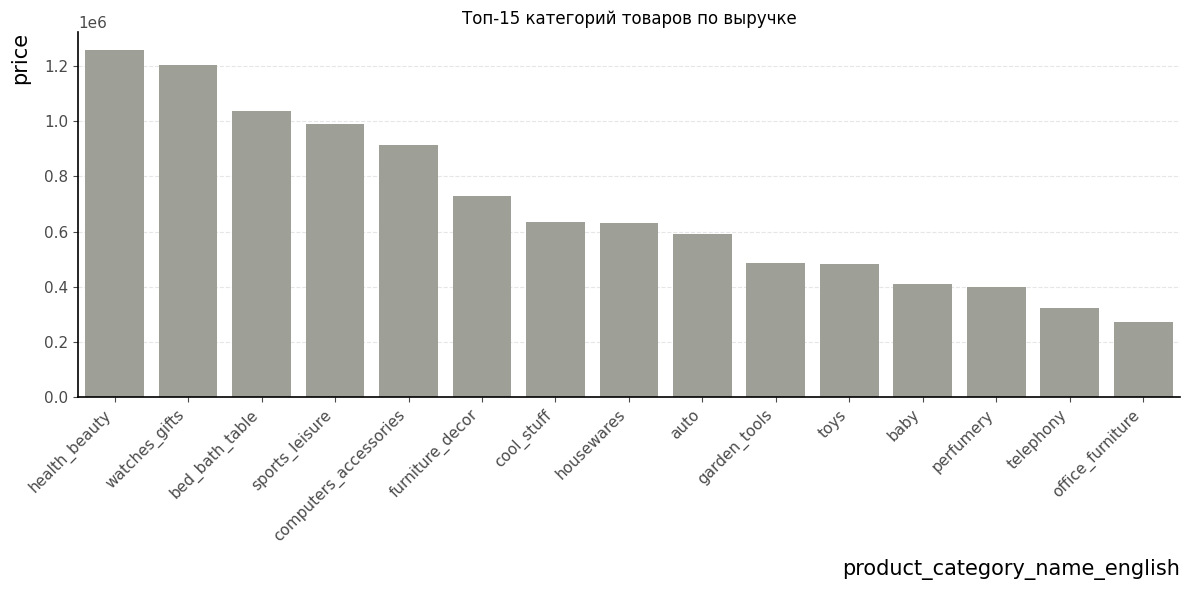

In [ ]:
plt.figure(figsize=(12, 6))
sns.barplot(data=df.groupby('product_category_name_english', as_index=False)['price'].sum().sort_values(by='price', ascending=False).head(15), x='product_category_name_english', y='price', color='#9FA096')

plt.xticks(rotation=45, ha='right')
plt.title('Топ-15 категорий товаров по выручке')
plt.tight_layout()
plt.show()

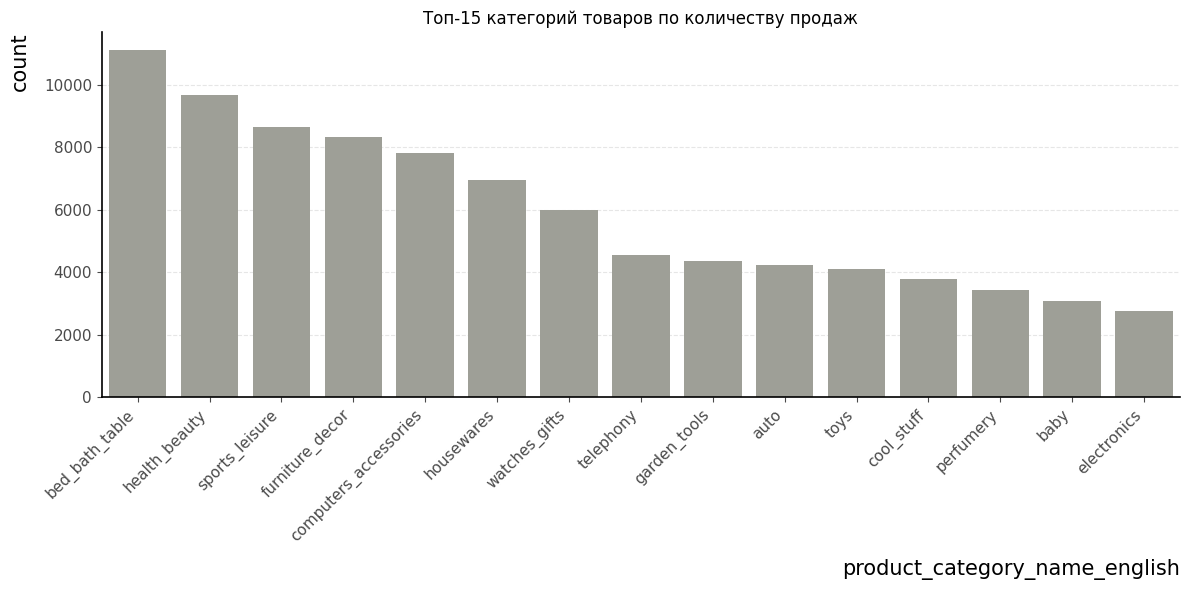

In [ ]:
plt.figure(figsize=(12, 6))
sns.barplot(data=df.groupby('product_category_name_english', as_index=False)['price'].count().sort_values(by='price', ascending=False).head(15), x='product_category_name_english', y='price', color='#9FA096')

plt.xticks(rotation=45, ha='right')
plt.ylabel("count")
plt.title('Топ-15 категорий товаров по количеству продаж')
plt.tight_layout()
plt.show()

In [ ]:
delivered_orders

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,month
30710,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04 00:00:00,2016-09
40692,cb29497c3782a76b57327c055d58b0e0,663c23427108785957931a3ac88f6085,delivered,2016-10-04 16:41:59,2016-10-06 15:55:55,2016-10-24 07:05:30,2016-10-29 12:53:41,2016-11-28 00:00:00,2016-10
24708,0ca768c507d1fc3c61bd950bb1c5231a,b3fb50a69d9de3ee23504d2cd66da13f,delivered,2016-10-10 15:20:14,2016-10-10 16:02:25,2016-10-30 11:23:50,2016-11-07 14:51:45,2016-12-06 00:00:00,2016-10
94421,2e8e21db96a8ab922e51cd297678c6b2,6a58b195be76f8ad6544e032b6c7316b,delivered,2016-10-09 12:13:58,2016-10-10 01:16:09,2016-10-25 13:54:41,2016-10-28 14:11:47,2016-12-02 00:00:00,2016-10
53268,25f680bf746bec3df11d48318ff015de,fd997caf29864e0b5e0d328a2d163e3f,delivered,2016-10-09 22:42:35,2016-10-10 11:02:43,2016-10-27 17:11:35,2016-11-01 18:04:41,2016-12-02 00:00:00,2016-10
...,...,...,...,...,...,...,...,...,...
17027,13bc75256bad09f3273a88f49cff00e1,1601b57bba160dc36168915123bd9278,delivered,2018-08-13 21:50:00,2018-08-13 22:04:16,2018-08-14 13:10:00,2018-08-15 21:56:46,2018-08-16 00:00:00,2018-08
40142,ea74d355b16bf9de1c103719173cb804,ce57da1d592e7f5a8606eca47d71664a,delivered,2018-08-06 10:10:27,2018-08-06 10:24:50,2018-08-14 10:56:00,2018-08-15 20:37:45,2018-08-17 00:00:00,2018-08
86685,0f8415c6898be42b337b26a77fcecbee,989f677f902616c785e3681d2fe63b75,delivered,2018-08-01 11:11:04,2018-08-01 12:30:36,2018-08-03 13:50:00,2018-08-10 18:18:21,2018-08-20 00:00:00,2018-08
78091,597c2563d00470ca79904967e0cd6595,cb03cd9878a7746a45adcbf027f2098a,delivered,2018-08-22 19:14:34,2018-08-22 19:25:18,2018-08-23 12:33:00,2018-08-24 14:13:43,2018-08-29 00:00:00,2018-08


In [ ]:
delivered_payments = pd.merge(
    delivered_orders,
    payments,
    on='order_id',
    how='inner'
)

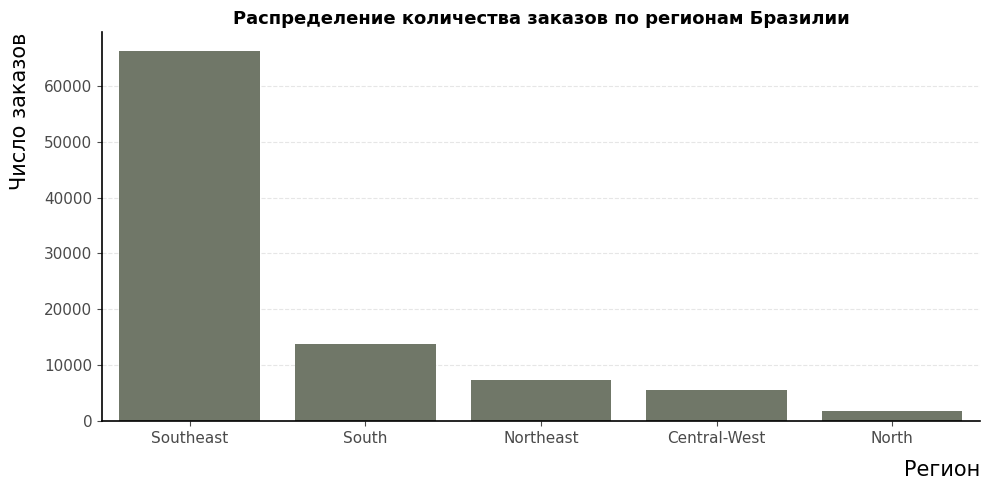

In [ ]:
# 1. Объединяем платежи с таблицей клиентов, чтобы забрать штат
df_with_states = delivered_payments.merge(
    customers[["customer_id", "customer_state"]], on="customer_id", how="left"
)

# 2. Словарь макрорегионов
macro_regions = {
    "SP": "Southeast",
    "RJ": "Southeast",
    "MG": "Southeast",
    "ES": "Southeast",
    "PR": "South",
    "RS": "South",
    "SC": "South",
    "BA": "Northeast",
    "CE": "Northeast",
    "MA": "Northeast",
    "PB": "Northeast",
    "RN": "Northeast",
    "AL": "Northeast",
    "SE": "Northeast",
    "PI": "Northeast",
    "DF": "Central-West",
    "GO": "Central-West",
    "MT": "Central-West",
    "MS": "Central-West",
    "AM": "North",
    "PA": "North",
    "RO": "North",
    "TO": "North",
    "AC": "North",
    "AP": "North",
    "RR": "North",
}

# 3. Добавляем макрорегион и группируем по нему
df_with_states["macro_region"] = df_with_states["customer_state"].map(
    macro_regions
)
region_orders = (
    df_with_states.groupby("macro_region", as_index=False)["order_id"]
    .nunique()
    .sort_values(by="order_id", ascending=False)
)

# 4. Строим график
plt.figure(figsize=(10, 5))
sns.barplot(
    data=region_orders,
    x="macro_region",
    y="order_id",
    color='#707A65' ,
    legend=False,
)

plt.title(
    "Распределение количества заказов по регионам Бразилии",
    fontsize=13,
    weight="bold",
)
plt.xlabel("Регион")
plt.ylabel("Число заказов")
plt.tight_layout()
plt.show()


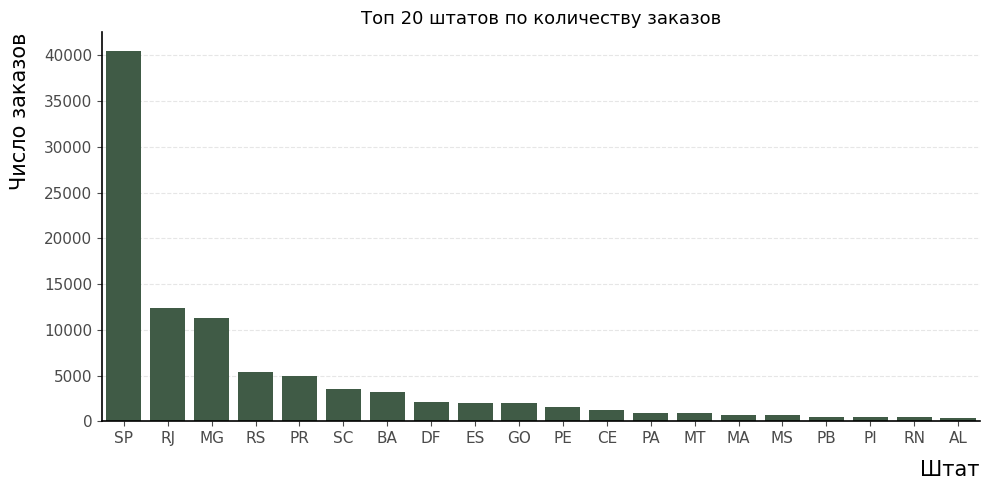

In [ ]:
state_orders = (
    df_with_states.groupby("customer_state", as_index=False)["order_id"]
    .nunique()
    .sort_values(by="order_id", ascending=False)
    .head(20)
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=state_orders,
    x="customer_state",
    y="order_id",
    color='#3B5F43',
    legend=False,
)

plt.title(
    "Топ 20 штатов по количеству заказов",
    fontsize=13
)
plt.xlabel("Штат")
plt.ylabel("Число заказов")
plt.tight_layout()
plt.show()

In [ ]:
customers.columns

Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state'],
      dtype='object')

In [ ]:
delivered_payments.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'month', 'payment_sequential', 'payment_type', 'payment_installments',
       'payment_value'],
      dtype='object')

In [ ]:
df_with_cities = delivered_payments.merge(
    customers[["customer_id", 'customer_city']], on="customer_id", how="left"
)

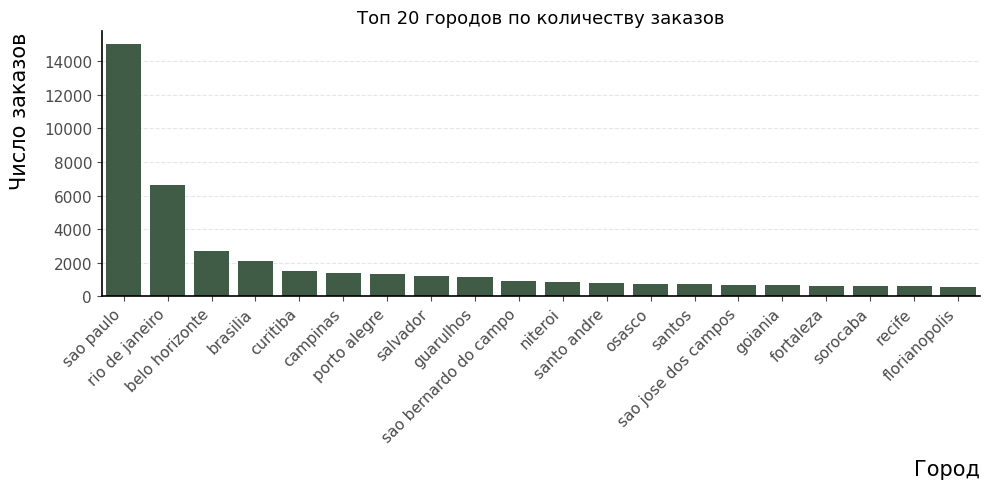

In [ ]:
city_orders = (
    df_with_cities.groupby('customer_city', as_index=False)["order_id"]
    .nunique()
    .sort_values(by="order_id", ascending=False)
    .head(20)
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=city_orders,
    x="customer_city",
    y="order_id",
    color='#3B5F43',
    legend=False,
)

plt.title(
    "Топ 20 городов по количеству заказов",
    fontsize=13
)
plt.xlabel("Город")
plt.xticks(rotation=45, ha='right')
plt.ylabel("Число заказов")
plt.tight_layout()
plt.show()

# Расчет продуктовых метрик

Посчитаем основные продуктовые метрики и посмотрим на их динамику

### GMV(Gross Merchandise Volume), ARPPU и AOV(Average Order Value)

In [ ]:
delivered_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,month
30710,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04 00:00:00,2016-09
40692,cb29497c3782a76b57327c055d58b0e0,663c23427108785957931a3ac88f6085,delivered,2016-10-04 16:41:59,2016-10-06 15:55:55,2016-10-24 07:05:30,2016-10-29 12:53:41,2016-11-28 00:00:00,2016-10
24708,0ca768c507d1fc3c61bd950bb1c5231a,b3fb50a69d9de3ee23504d2cd66da13f,delivered,2016-10-10 15:20:14,2016-10-10 16:02:25,2016-10-30 11:23:50,2016-11-07 14:51:45,2016-12-06 00:00:00,2016-10
94421,2e8e21db96a8ab922e51cd297678c6b2,6a58b195be76f8ad6544e032b6c7316b,delivered,2016-10-09 12:13:58,2016-10-10 01:16:09,2016-10-25 13:54:41,2016-10-28 14:11:47,2016-12-02 00:00:00,2016-10
53268,25f680bf746bec3df11d48318ff015de,fd997caf29864e0b5e0d328a2d163e3f,delivered,2016-10-09 22:42:35,2016-10-10 11:02:43,2016-10-27 17:11:35,2016-11-01 18:04:41,2016-12-02 00:00:00,2016-10


In [ ]:
customers.columns

Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state'],
      dtype='object')

In [ ]:
delivered_orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'month'],
      dtype='object')

In [ ]:
customers["customer_unique_id"].nunique()

96096

In [ ]:
customers["customer_id"].nunique()

99441

In [ ]:
orders["customer_id"].nunique()

99441

In [ ]:
merged_del_orders_customers = pd.merge(left=delivered_orders, right=customers, on="customer_id", how="left")

In [ ]:
merged_del_orders_customers['total_unique_user_orders'] = (
    merged_del_orders_customers.groupby('customer_unique_id')['order_id']
    .transform('count')
)

In [ ]:
orders_distribution = (
    merged_del_orders_customers.groupby('total_unique_user_orders')['customer_unique_id']
    .nunique()
    .reset_index(name='unique_customers_count')
)

print(orders_distribution)

   total_unique_user_orders  unique_customers_count
0                         1                   90557
1                         2                    2573
2                         3                     181
3                         4                      28
4                         5                       9
5                         6                       5
6                         7                       3
7                         9                       1
8                        15                       1


In [ ]:
print(f"TPV: {delivered_payments['payment_value'].sum()}")
print(f"AOV: {round((delivered_payments['payment_value'].sum() / delivered_payments['order_id'].nunique()), 1)}")

TPV: 15422461.77
AOV: 159.9


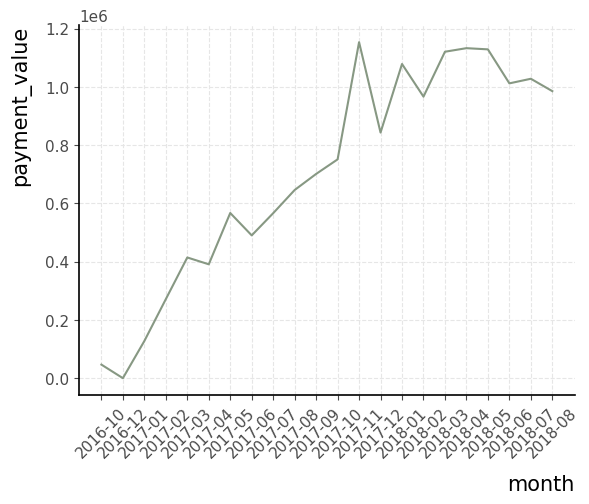

In [ ]:
sns.lineplot(data=delivered_payments.groupby("month", as_index=False)['payment_value'].sum(), x='month', y='payment_value', color="#879883", )
plt.xticks(rotation=45)
plt.show()

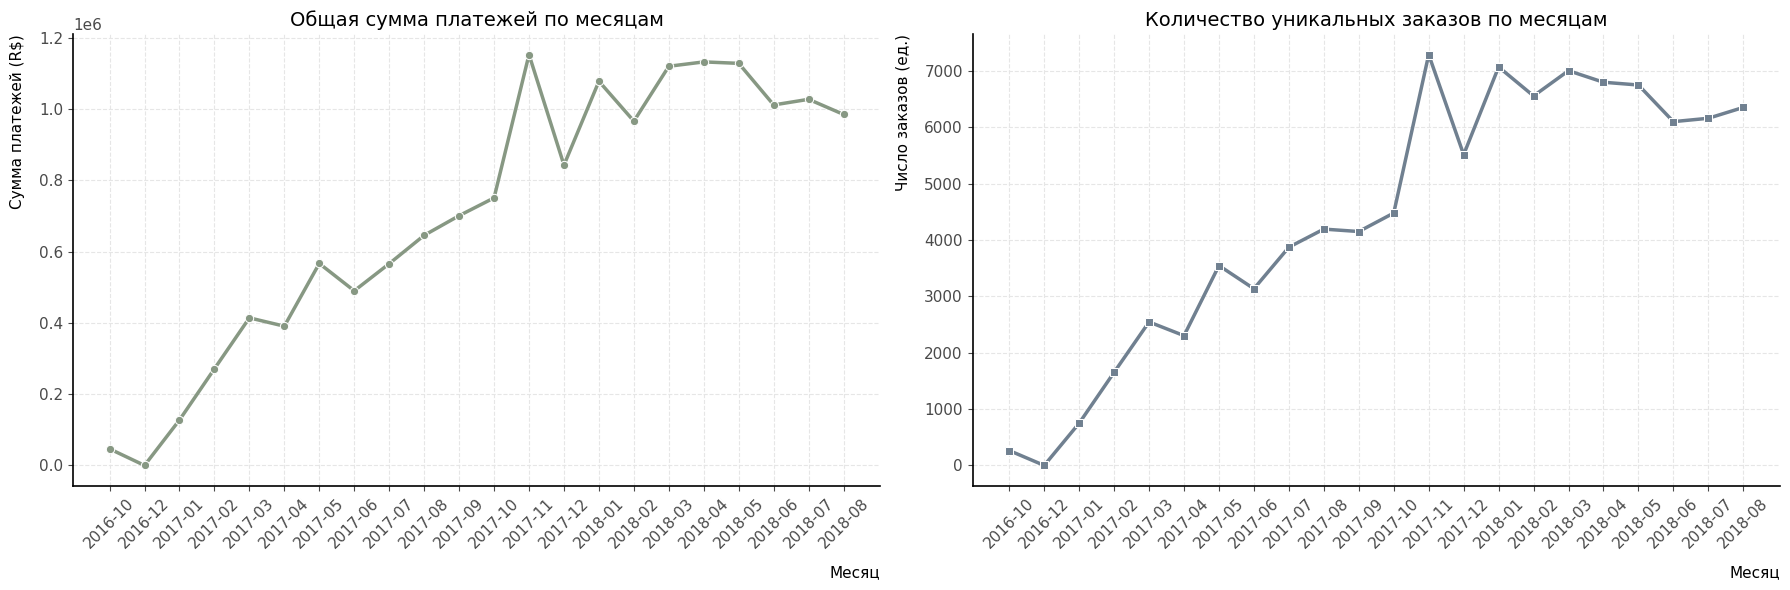

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))


revenue_data = delivered_payments.groupby("month", as_index=False)[
    "payment_value"
].sum()

sns.lineplot(
    data=revenue_data,
    x="month",
    y="payment_value",
    color="#879883",
    marker="o",
    linewidth=2.5,
    ax=axes[0],
)
axes[0].set_title("Общая сумма платежей по месяцам", fontsize=14)
axes[0].set_xlabel("Месяц", fontsize=11)
axes[0].set_ylabel("Сумма платежей (R$)", fontsize=11)
axes[0].tick_params(axis="x", rotation=45)

orders_count_data = delivered_payments.groupby("month", as_index=False)[
    "order_id"
].nunique()

sns.lineplot(
    data=orders_count_data,
    x="month",
    y="order_id",
    color="slategrey",
    marker="s",
    linewidth=2.5,
    ax=axes[1],
)
axes[1].set_title(
    "Количество уникальных заказов по месяцам", fontsize=14
)
axes[1].set_xlabel("Месяц", fontsize=11)
axes[1].set_ylabel("Число заказов (ед.)", fontsize=11)
axes[1].tick_params(axis="x", rotation=45)


plt.tight_layout()
plt.show()


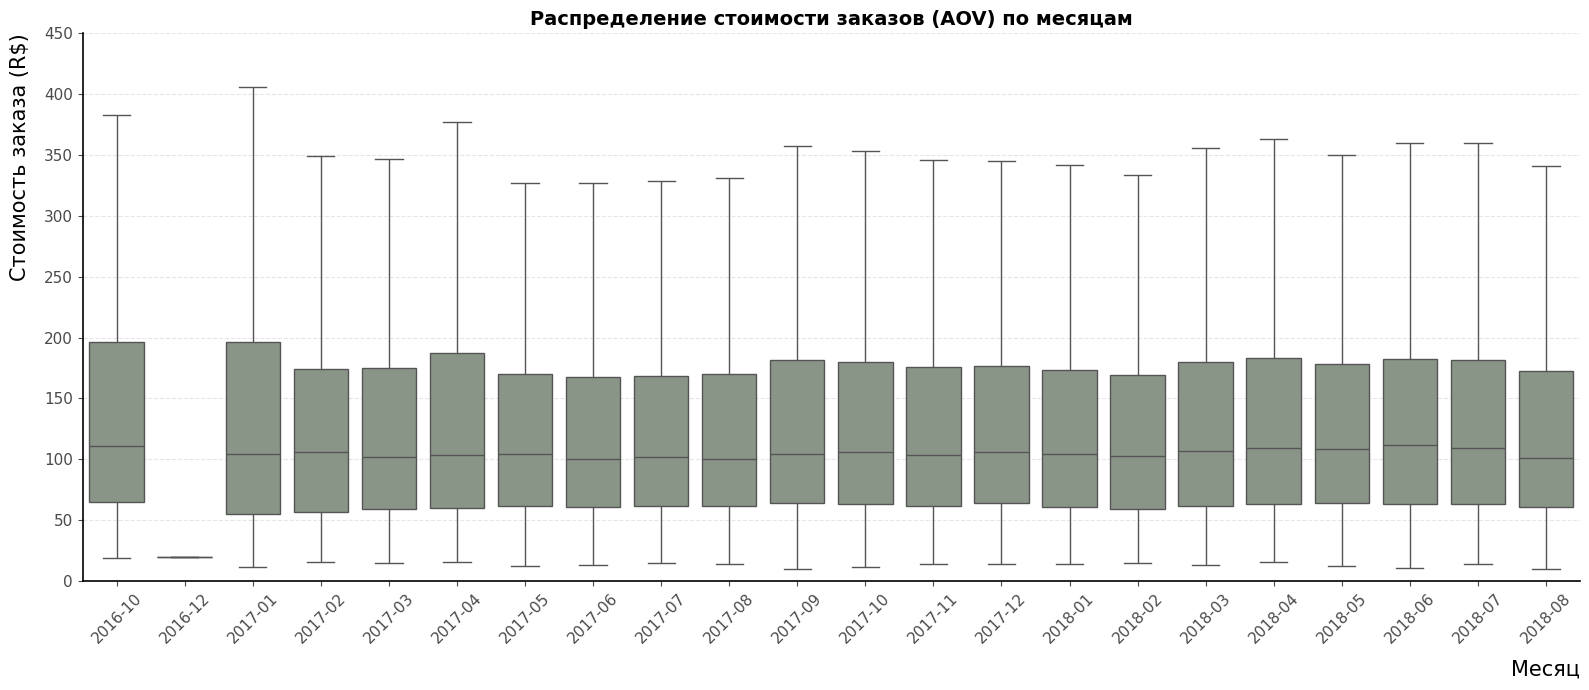

In [ ]:

order_aov_data = (
    delivered_payments.groupby(["month", "order_id"], as_index=False)[
        "payment_value"
    ].sum()
)


plt.figure(figsize=(16, 7))
sns.boxplot(
    data=order_aov_data,
    x="month",
    y="payment_value",
    color="#879883",
    showfliers=False,
)

plt.title(
    "Распределение стоимости заказов (AOV) по месяцам",
    fontsize=14,
    weight="bold",
)
plt.xlabel("Месяц")
plt.ylabel("Стоимость заказа (R$)")
plt.xticks(rotation=45)
plt.ylim(0, 450)

plt.tight_layout()
plt.show()


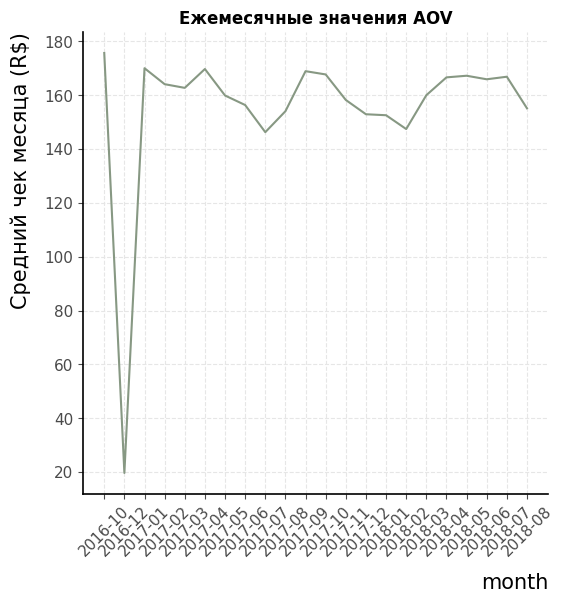

In [ ]:

monthly_aov = (
    delivered_payments.groupby(["month", "order_id"])["payment_value"]
    .sum()
    .groupby("month")
    .mean()
    .reset_index(name="AOV")
)


plt.figure(figsize=(6, 6))
sns.lineplot(data=monthly_aov, y="AOV", x="month", color="#879883")

plt.xticks(rotation=45)
plt.title("Ежемесячные значения AOV", fontsize=12, weight="bold")
plt.ylabel("Средний чек месяца (R$)")
plt.show()


In [ ]:
# 1. Объединяем доставленные заказы с позициями товаров
items_delivered = pd.merge(
    delivered_orders[['order_id']],
    items[['order_id', 'price', 'freight_value']],
    on='order_id'
)

# 2. Чистый оборот товаров (здесь суммирование по каждой позиции корректно)
pure_merchandise_value = items_delivered['price'].sum()

# 3. ПРАВИЛЬНЫЙ РАСЧЕТ ДОСТАВКИ: Находим честную стоимость доставки для каждого уникального заказа
# (Группируем по заказу и берем max, чтобы избежать дублирования на уровне позиций)
freight_per_order = items_delivered.groupby('order_id')['freight_value'].max()
total_freight_value = freight_per_order.sum()

# 4. Моделируем выручку Olist (15% с товаров + 5% с правильной доставки)
olist_revenue_from_goods = pure_merchandise_value * 0.15
olist_revenue_from_freight = total_freight_value * 0.05
olist_total_estimated_revenue = olist_revenue_from_goods + olist_revenue_from_freight

# 5. Расчет ARPPU Olist на одного уникального платящего пользователя
total_paying_users = customers['customer_unique_id'].nunique()
arppu_olist = olist_total_estimated_revenue / total_paying_users

# 6. Вывод результатов
print(f"Оборот товаров (Чистый GMV): {pure_merchandise_value:,.2f} R$")
print(f"Оборот доставки (Честный, без дублей): {total_freight_value:,.2f} R$")
print("-" * 40)
print(f"Выручка Olist с товаров (15%): {olist_revenue_from_goods:,.2f} R$")
print(f"Выручка Olist с доставки (5%): {olist_revenue_from_freight:,.2f} R$")
print(f"ОБЩАЯ ПРИМЕРНАЯ ВЫРУЧКА OLIST: {olist_total_estimated_revenue:,.2f} R$")
print(f"ARPPU Olist (доход компании на 1 клиента): {arppu_olist:.2f} R$")


Оборот товаров (Чистый GMV): 13,221,498.11 R$
Оборот доставки (Честный, без дублей): 1,959,420.15 R$
----------------------------------------
Выручка Olist с товаров (15%): 1,983,224.72 R$
Выручка Olist с доставки (5%): 97,971.01 R$
ОБЩАЯ ПРИМЕРНАЯ ВЫРУЧКА OLIST: 2,081,195.72 R$
ARPPU Olist (доход компании на 1 клиента): 21.66 R$


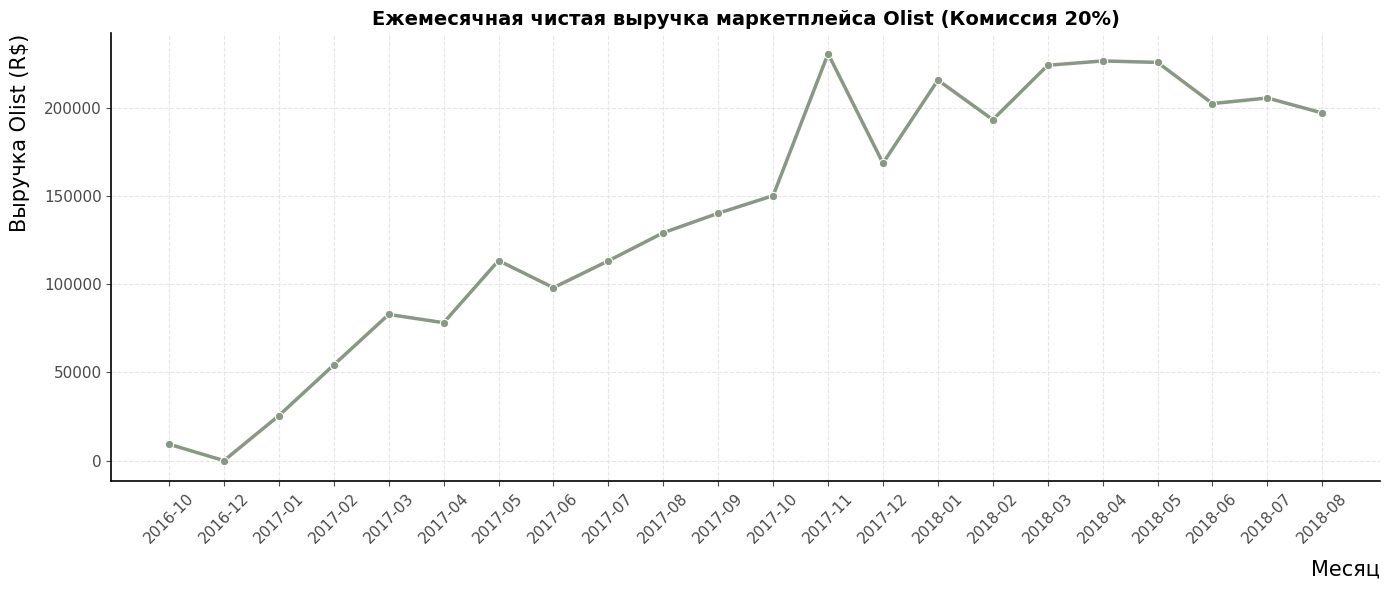

In [ ]:
# 1. Считаем общую сумму оплат за каждый месяц (GMV)
monthly_gmv = delivered_payments.groupby("month", as_index=False)[
    "payment_value"
].sum()

# 2. Выделяем комиссию Olist (20% от оборота)
monthly_gmv["olist_revenue"] = monthly_gmv["payment_value"] * 0.20

# 3. Строим график выручки маркетплейса
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=monthly_gmv,
    x="month",
    y="olist_revenue",
    color="#879883",
    marker="o",
    linewidth=2.5,
)

plt.title(
    "Ежемесячная чистая выручка маркетплейса Olist (Комиссия 20%)",
    fontsize=14,
    weight="bold",
)
plt.xlabel("Месяц")
plt.ylabel("Выручка Olist (R$)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


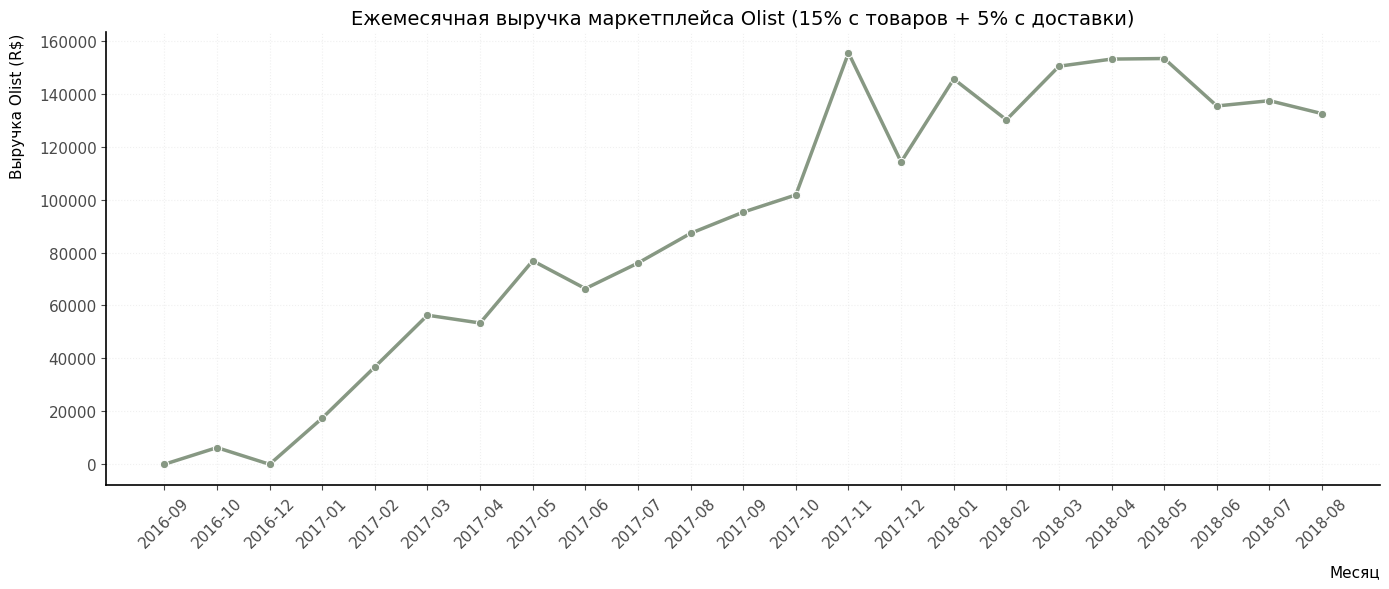

In [ ]:
# 1. Объединяем доставленные заказы с позициями товаров для сохранения временных меток (month)
items_monthly = pd.merge(
    delivered_orders[["order_id", "month"]],
    items[["order_id", "price", "freight_value"]],
    on="order_id",
)

# 2. Считаем ежемесячный чистый оборот товаров (суммирование по позициям)
monthly_goods = (
    items_monthly.groupby("month")["price"].sum().reset_index(name="goods_value")
)

# 3. Считаем ежемесячный честный оборот доставки (сначала дедупликация max() внутри заказа, затем сумма)
monthly_freight = (
    items_monthly.groupby(["month", "order_id"])["freight_value"]
    .max()
    .groupby("month")
    .sum()
    .reset_index(name="freight_value")
)

# 4. Объединяем показатели и моделируем выручку Olist (15% с товаров + 5% с доставки)
monthly_financials = pd.merge(monthly_goods, monthly_freight, on="month")
monthly_financials["olist_revenue"] = (
    monthly_financials["goods_value"] * 0.15
    + monthly_financials["freight_value"] * 0.05
)

# 5. Строим график выручки маркетплейса
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=monthly_financials,
    x="month",
    y="olist_revenue",
    color="#879883",
    marker="o",
    linewidth=2.5,
)

plt.title(
    "Ежемесячная выручка маркетплейса Olist (15% с товаров + 5% с доставки)",
    fontsize=14
)
plt.xlabel("Месяц", fontsize=11)
plt.ylabel("Выручка Olist (R$)", fontsize=11)
plt.xticks(rotation=45)
plt.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


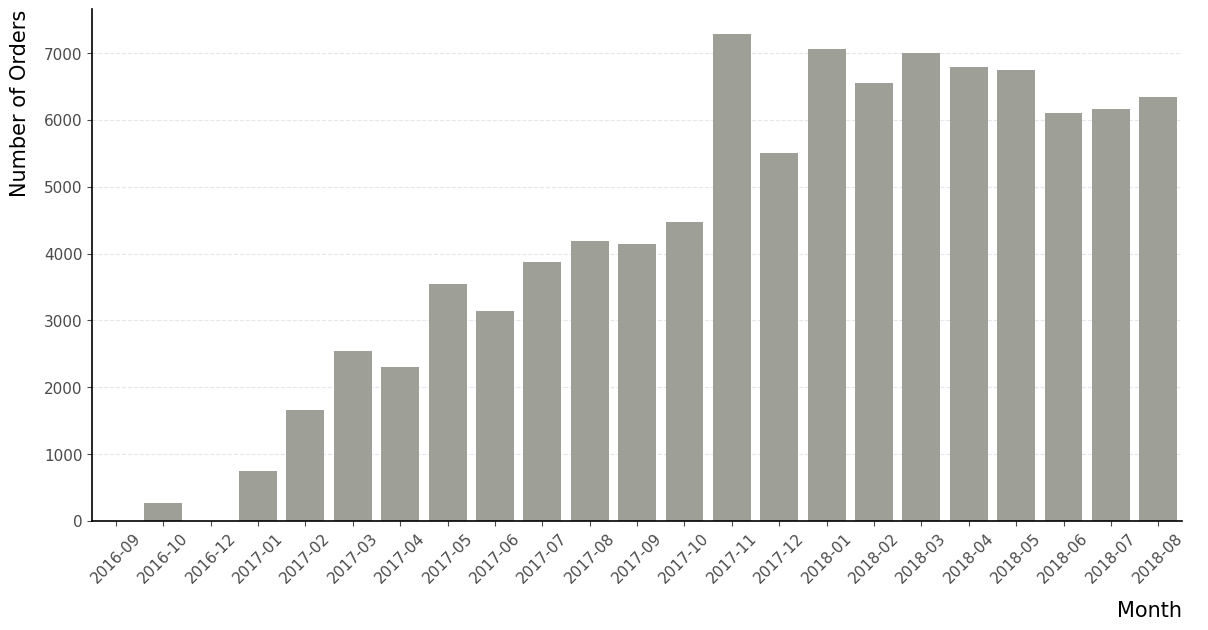

In [ ]:
g = sns.catplot(
    data=delivered_orders,
    x='month',
    kind='count',
    color='#9FA096',
    height=6,
    aspect=2
)


g.set_xticklabels(rotation=45)
g.set_axis_labels("Month", "Number of Orders")

plt.show()

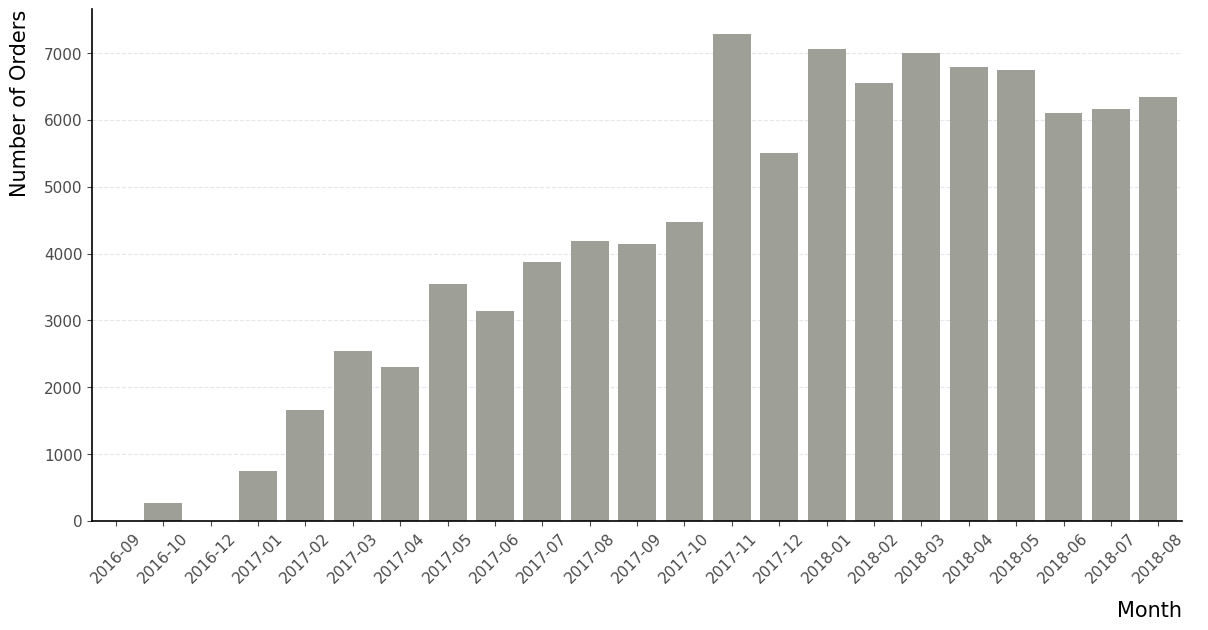

In [ ]:
g = sns.catplot(
    data=delivered_orders,
    x='month',
    kind='count',
    color='#9FA096',
    height=6,
    aspect=2
)


g.set_xticklabels(rotation=45)
g.set_axis_labels("Month", "Number of Orders")

plt.show()

In [ ]:
delivered_orders

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,month
30710,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04 00:00:00,2016-09
40692,cb29497c3782a76b57327c055d58b0e0,663c23427108785957931a3ac88f6085,delivered,2016-10-04 16:41:59,2016-10-06 15:55:55,2016-10-24 07:05:30,2016-10-29 12:53:41,2016-11-28 00:00:00,2016-10
24708,0ca768c507d1fc3c61bd950bb1c5231a,b3fb50a69d9de3ee23504d2cd66da13f,delivered,2016-10-10 15:20:14,2016-10-10 16:02:25,2016-10-30 11:23:50,2016-11-07 14:51:45,2016-12-06 00:00:00,2016-10
94421,2e8e21db96a8ab922e51cd297678c6b2,6a58b195be76f8ad6544e032b6c7316b,delivered,2016-10-09 12:13:58,2016-10-10 01:16:09,2016-10-25 13:54:41,2016-10-28 14:11:47,2016-12-02 00:00:00,2016-10
53268,25f680bf746bec3df11d48318ff015de,fd997caf29864e0b5e0d328a2d163e3f,delivered,2016-10-09 22:42:35,2016-10-10 11:02:43,2016-10-27 17:11:35,2016-11-01 18:04:41,2016-12-02 00:00:00,2016-10
...,...,...,...,...,...,...,...,...,...
17027,13bc75256bad09f3273a88f49cff00e1,1601b57bba160dc36168915123bd9278,delivered,2018-08-13 21:50:00,2018-08-13 22:04:16,2018-08-14 13:10:00,2018-08-15 21:56:46,2018-08-16 00:00:00,2018-08
40142,ea74d355b16bf9de1c103719173cb804,ce57da1d592e7f5a8606eca47d71664a,delivered,2018-08-06 10:10:27,2018-08-06 10:24:50,2018-08-14 10:56:00,2018-08-15 20:37:45,2018-08-17 00:00:00,2018-08
86685,0f8415c6898be42b337b26a77fcecbee,989f677f902616c785e3681d2fe63b75,delivered,2018-08-01 11:11:04,2018-08-01 12:30:36,2018-08-03 13:50:00,2018-08-10 18:18:21,2018-08-20 00:00:00,2018-08
78091,597c2563d00470ca79904967e0cd6595,cb03cd9878a7746a45adcbf027f2098a,delivered,2018-08-22 19:14:34,2018-08-22 19:25:18,2018-08-23 12:33:00,2018-08-24 14:13:43,2018-08-29 00:00:00,2018-08


In [ ]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [ ]:
items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [ ]:
items.shape

(112650, 7)

In [ ]:
items[items["order_id"] == "00143d0f86d6fbd9f9b38ab440ac16f5"]

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
32,00143d0f86d6fbd9f9b38ab440ac16f5,1,e95ee6822b66ac6058e2e4aff656071a,a17f621c590ea0fab3d5d883e1630ec6,2017-10-20 16:07:52,21.33,15.1
33,00143d0f86d6fbd9f9b38ab440ac16f5,2,e95ee6822b66ac6058e2e4aff656071a,a17f621c590ea0fab3d5d883e1630ec6,2017-10-20 16:07:52,21.33,15.1
34,00143d0f86d6fbd9f9b38ab440ac16f5,3,e95ee6822b66ac6058e2e4aff656071a,a17f621c590ea0fab3d5d883e1630ec6,2017-10-20 16:07:52,21.33,15.1


In [ ]:
delivered_orders_items

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,month
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29 00:00:00,2017-09
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15 00:00:00,2017-04
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05 00:00:00,2018-01
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20 00:00:00,2018-08
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17 00:00:00,2017-02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112645,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41,b51593916b4b8e0d6f66f2ae24f2673d,delivered,2018-04-23 13:57:06,2018-04-25 04:11:01,2018-04-25 12:09:00,2018-05-10 22:56:40,2018-05-18 00:00:00,2018-04
112646,fffcd46ef2263f404302a634eb57f7eb,1,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:48,350.00,36.53,84c5d4fbaf120aae381fad077416eaa0,delivered,2018-07-14 10:26:46,2018-07-17 04:31:48,2018-07-17 08:05:00,2018-07-23 20:31:55,2018-08-01 00:00:00,2018-07
112647,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95,29309aa813182aaddc9b259e31b870e6,delivered,2017-10-23 17:07:56,2017-10-24 17:14:25,2017-10-26 15:13:14,2017-10-28 12:22:22,2017-11-10 00:00:00,2017-10
112648,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72,b5e6afd5a41800fdf401e0272ca74655,delivered,2017-08-14 23:02:59,2017-08-15 00:04:32,2017-08-15 19:02:53,2017-08-16 21:59:40,2017-08-25 00:00:00,2017-08


In [ ]:
profit_by_month = pd.merge(left = delivered_orders, right = payments.groupby('order_id', as_index=False)['payment_value'].sum(), how = 'left', on='order_id')\
.groupby('month', as_index=False)['payment_value'].sum()

In [ ]:
profit_by_month

,month,payment_value
0,2016-09,0.00
1,2016-10,46566.71
2,2016-12,19.62
3,2017-01,127545.67
4,2017-02,271298.65
...,...,...
18,2018-04,1132933.95
19,2018-05,1128836.69
20,2018-06,1012090.68
21,2018-07,1027903.86


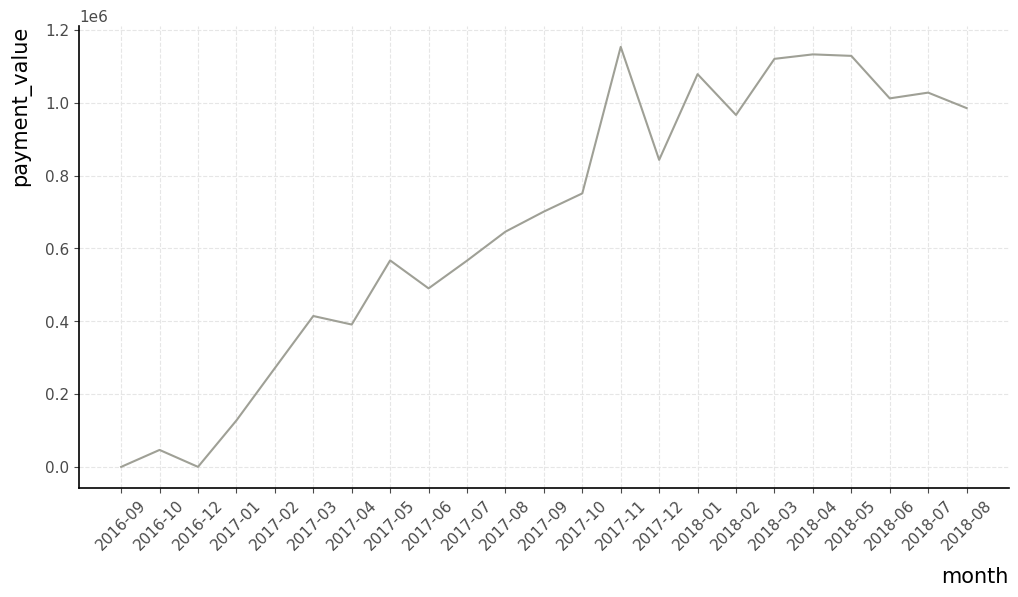

In [ ]:
plt.figure(figsize=(12,6))
sns.lineplot(data=profit_by_month, x='month', y = 'payment_value', color='#9FA096')
plt.xticks(rotation=45)
plt.show()

In [ ]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [ ]:
products.product_category_name.nunique()

73

In [ ]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [ ]:
customers.customer_state.nunique()

27

### Retention Rate, MAU

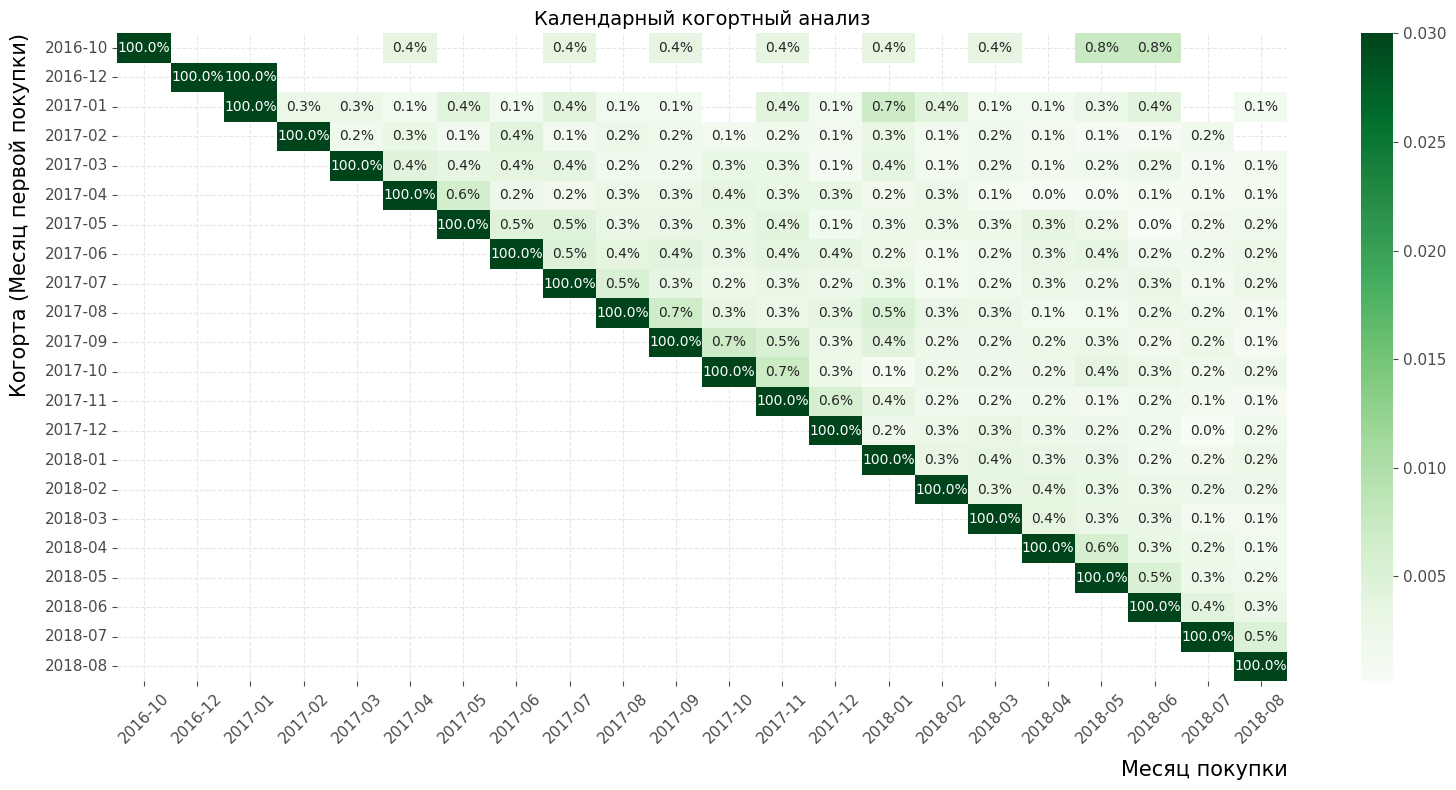

In [ ]:
# 1. Привязываем уникальный ID клиента и переводим даты в строки "Год-Месяц"
df_retention = delivered_payments.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left",
)
df_retention["month_dt"] = pd.to_datetime(df_retention["month"])
df_retention["cohort_dt"] = df_retention.groupby("customer_unique_id")[
    "month_dt"
].transform("min")

df_retention["cohort"] = df_retention["cohort_dt"].dt.strftime("%Y-%m")
df_retention["month_str"] = df_retention["month_dt"].dt.strftime("%Y-%m")

# 2. Строим календарную матрицу (в столбцах — реальные месяцы покупок)
# Это автоматически дает сдвиг вправо по диагонали
cohort_calendar_matrix = (
    df_retention.groupby(["cohort", "month_str"])["customer_unique_id"]
    .nunique()
    .unstack()
).sort_index(axis=0).sort_index(axis=1)

# 3. Гарантированно вычищаем будущие периоды (все, что ниже/правее диагонали)
for r_idx, cohort in enumerate(cohort_calendar_matrix.index):
    if cohort in cohort_calendar_matrix.columns:
        c_idx = list(cohort_calendar_matrix.columns).index(cohort)
        # Все ячейки строго до диагонали и строго после максимального месяца зануляем/очищаем
        cohort_calendar_matrix.iloc[r_idx, :c_idx] = None

# 4. Считаем Retention: делим каждую ячейку на значение, стоящее строго на диагонали этой строки
# Перебираем строки и делим на значение из столбца, имя которого совпадает с именем строки (когорты)
diagonal_values = [
    cohort_calendar_matrix.loc[cohort, cohort]
    if cohort in cohort_calendar_matrix.columns
    else None
    for cohort in cohort_calendar_matrix.index
]

retention_calendar_matrix = cohort_calendar_matrix.div(
    diagonal_values, axis=0
)


plt.figure(figsize=(16, 8))
sns.heatmap(
    retention_calendar_matrix,
    annot=True,
    fmt=".1%",
    cmap="Greens",
    vmax=0.03,
)

plt.title(
    "Календарный когортный анализ",
    fontsize=14
)
plt.xlabel("Месяц покупки")
plt.ylabel("Когорта (Месяц первой покупки)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [ ]:
cohort_calendar_matrix = (
    df_retention.groupby(["cohort", "month_str"])["customer_unique_id"]
    .nunique()
    .unstack()
)

In [ ]:
cohort_calendar_matrix.sort_index(axis=0).sort_index(axis=1)

month_str,2016-10,2016-12,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,...,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
cohort,,,,,,,,,,,,,,,,,,,,,
2016-10,262.0,NaN,NaN,NaN,NaN,1.0,NaN,NaN,1.0,NaN,...,1.0,NaN,1.0,NaN,1.0,NaN,2.0,2.0,NaN,NaN
2016-12,NaN,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,NaN,NaN,717.0,2.0,2.0,1.0,3.0,1.0,3.0,1.0,...,3.0,1.0,5.0,3.0,1.0,1.0,2.0,3.0,NaN,1.0
2017-02,NaN,NaN,NaN,1628.0,3.0,5.0,2.0,7.0,2.0,4.0,...,3.0,2.0,5.0,2.0,3.0,2.0,1.0,1.0,3.0,NaN
2017-03,NaN,NaN,NaN,NaN,2503.0,11.0,9.0,10.0,9.0,4.0,...,8.0,2.0,9.0,3.0,5.0,3.0,4.0,6.0,2.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2018-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,6582.0,39.0,20.0,16.0,9.0
2018-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,6506.0,34.0,17.0,12.0
2018-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5878.0,25.0,16.0


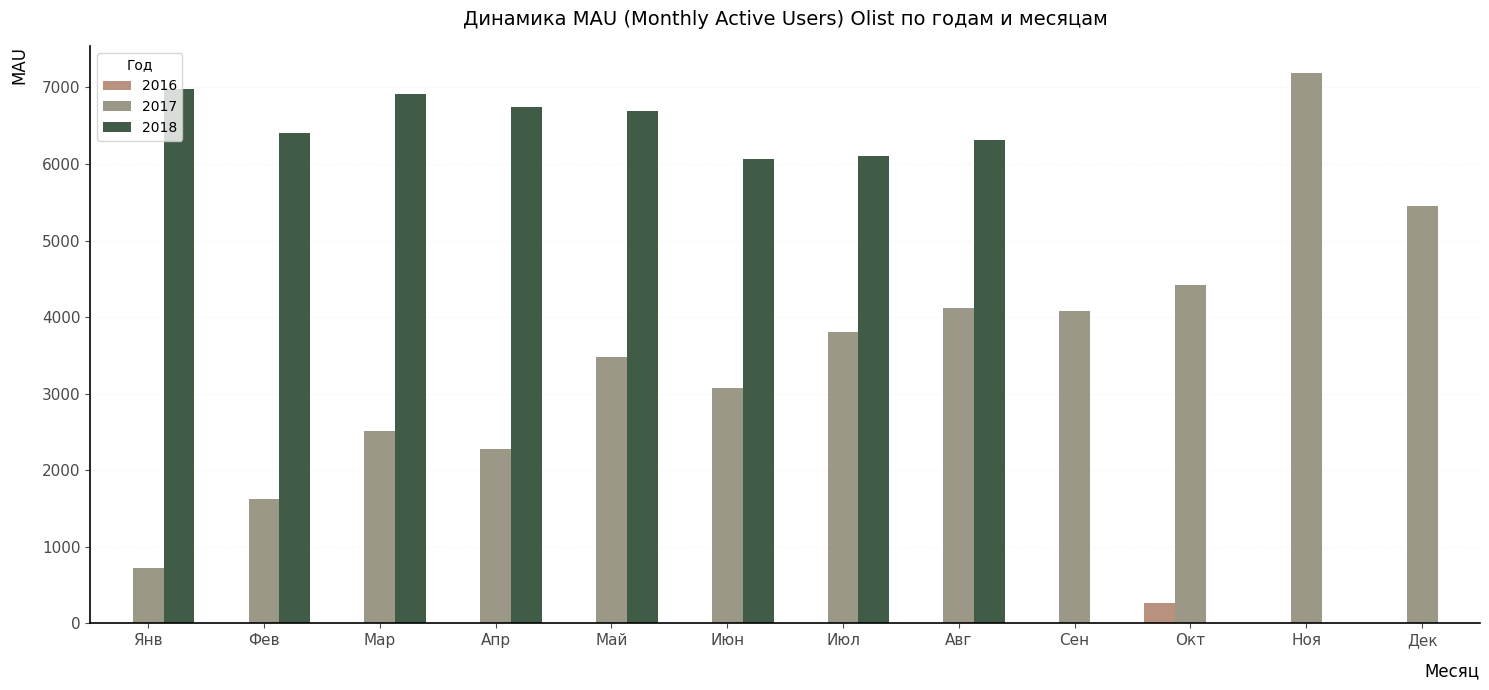

In [ ]:
# 1. Извлекаем год и порядковый номер месяца из даты покупки
merged_del_orders_customers['year'] = merged_del_orders_customers['order_purchase_timestamp'].dt.year
merged_del_orders_customers['month_num'] = merged_del_orders_customers['order_purchase_timestamp'].dt.month

# 2. Считаем MAU: количество уникальных клиентов в каждом месяце каждого года
mau_data = (
    merged_del_orders_customers.groupby(['year', 'month_num'])['customer_unique_id']
    .nunique()
    .reset_index(name='MAU')
)

# 3. Настройка параметров графика
plt.figure(figsize=(15, 7))

year_palette = {
    2016: '#C28D75',
    2017: '#9E9B84',
    2018: '#3B5F43'
}

# 4. Строим столбчатую диаграмму с группировкой по годам (hue)
sns.barplot(
    data=mau_data,
    x='month_num',
    y='MAU',
    hue='year',
    palette=year_palette
)

# 5. Оформление графика (заменяем номера месяцев 1-12 на текстовые метки)
month_names = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн', 'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек']
plt.xticks(ticks=range(12), labels=month_names)

plt.title("Динамика MAU (Monthly Active Users) Olist по годам и месяцам", fontsize=14, pad=15)
plt.xlabel("Месяц", fontsize=12)
plt.ylabel("MAU", fontsize=12)
plt.legend(title="Год", loc='upper left')
plt.grid(axis='y', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()


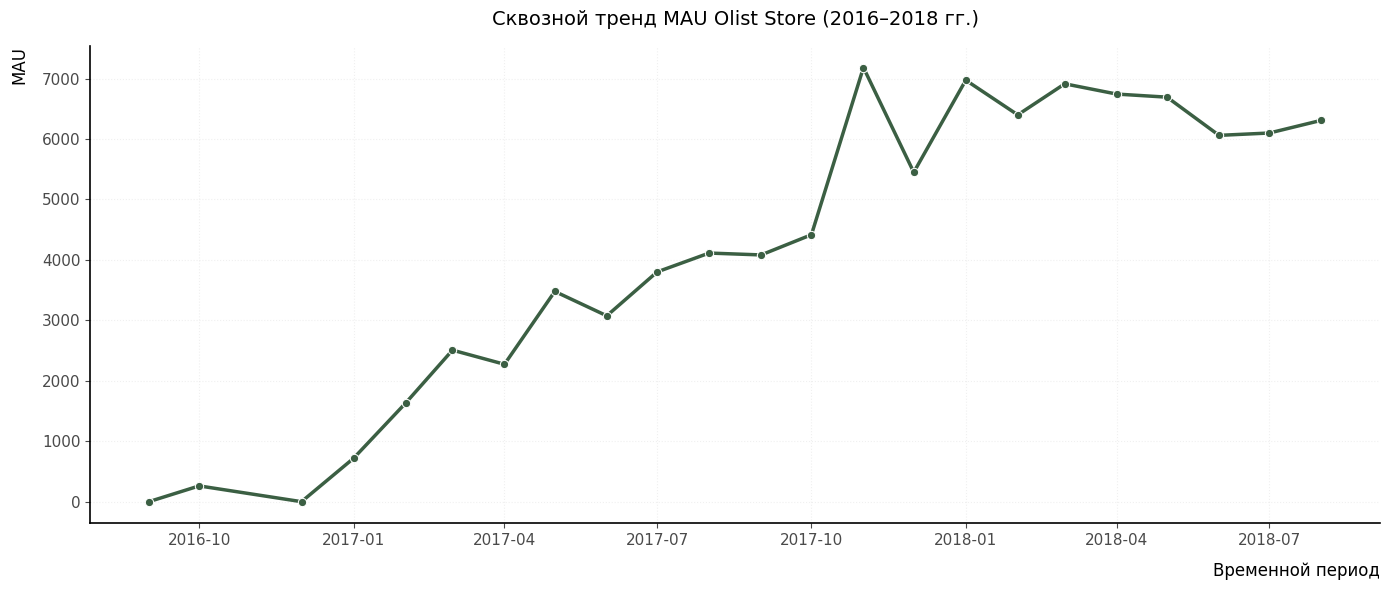

In [ ]:
# 1. Создаем непрерывную дату (первое число каждого месяца) для построения сквозной линии
merged_del_orders_customers['year_month'] = merged_del_orders_customers['order_purchase_timestamp'].dt.to_period('M').dt.to_timestamp()

# 2. Считаем сквозной MAU по месяцам
linear_mau = (
    merged_del_orders_customers.groupby('year_month')['customer_unique_id']
    .nunique()
    .reset_index(name='MAU')
)

# 3. Строим линейный график тренда
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=linear_mau,
    x='year_month',
    y='MAU',
    color='#3B5F43',  # Ваш темно-хвойный цвет
    marker='o',
    linewidth=2.5
)

# 4. Оформление графика
plt.title("Сквозной тренд MAU Olist Store (2016–2018 гг.)", fontsize=14, pad=15)
plt.xlabel("Временной период", fontsize=12)
plt.ylabel("MAU", fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


### Delivery Time, Delivery On-time и NPS (Net Promoter Score)

In [ ]:
delivered_orders.info()

<class 'pandas.core.frame.DataFrame'>
Index: 96478 entries, 30710 to 91225
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       96478 non-null  object        
 1   customer_id                    96478 non-null  object        
 2   order_status                   96478 non-null  object        
 3   order_purchase_timestamp       96478 non-null  datetime64[ns]
 4   order_approved_at              96464 non-null  object        
 5   order_delivered_carrier_date   96476 non-null  object        
 6   order_delivered_customer_date  96470 non-null  object        
 7   order_estimated_delivery_date  96478 non-null  object        
 8   month                          96478 non-null  object        
dtypes: datetime64[ns](1), object(8)
memory usage: 9.4+ MB


In [ ]:
delivered_orders['order_delivered_customer_date'] = pd.to_datetime(delivered_orders['order_delivered_customer_date'])

In [ ]:
delivered_orders["time_of_delivery"] = delivered_orders['order_delivered_customer_date'] - delivered_orders['order_purchase_timestamp']
delivered_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,month,time_of_delivery
30710,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04 00:00:00,2016-09,54 days 19:31:00
40692,cb29497c3782a76b57327c055d58b0e0,663c23427108785957931a3ac88f6085,delivered,2016-10-04 16:41:59,2016-10-06 15:55:55,2016-10-24 07:05:30,2016-10-29 12:53:41,2016-11-28 00:00:00,2016-10,24 days 20:11:42
24708,0ca768c507d1fc3c61bd950bb1c5231a,b3fb50a69d9de3ee23504d2cd66da13f,delivered,2016-10-10 15:20:14,2016-10-10 16:02:25,2016-10-30 11:23:50,2016-11-07 14:51:45,2016-12-06 00:00:00,2016-10,27 days 23:31:31
94421,2e8e21db96a8ab922e51cd297678c6b2,6a58b195be76f8ad6544e032b6c7316b,delivered,2016-10-09 12:13:58,2016-10-10 01:16:09,2016-10-25 13:54:41,2016-10-28 14:11:47,2016-12-02 00:00:00,2016-10,19 days 01:57:49
53268,25f680bf746bec3df11d48318ff015de,fd997caf29864e0b5e0d328a2d163e3f,delivered,2016-10-09 22:42:35,2016-10-10 11:02:43,2016-10-27 17:11:35,2016-11-01 18:04:41,2016-12-02 00:00:00,2016-10,22 days 19:22:06


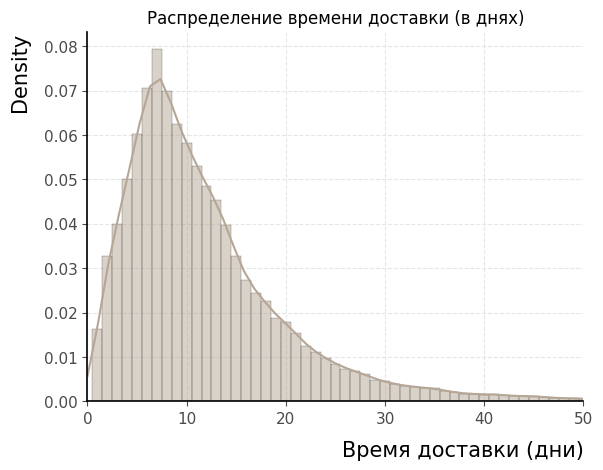

In [ ]:
delivered_orders['time_of_delivery_days'] = delivered_orders['time_of_delivery'].dt.days
clean_orders = delivered_orders[delivered_orders['time_of_delivery_days'] >= 0]
sns.histplot(data=clean_orders, x="time_of_delivery_days", color='#B5A695', kde=True, stat='density', discrete=True)
plt.title("Распределение времени доставки (в днях)")
plt.xlabel("Время доставки (дни)")
plt.xlim(0,50)
plt.show()

/tmp/ipykernel_1384/2997502235.py:38: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title="Статус выполнения плана")


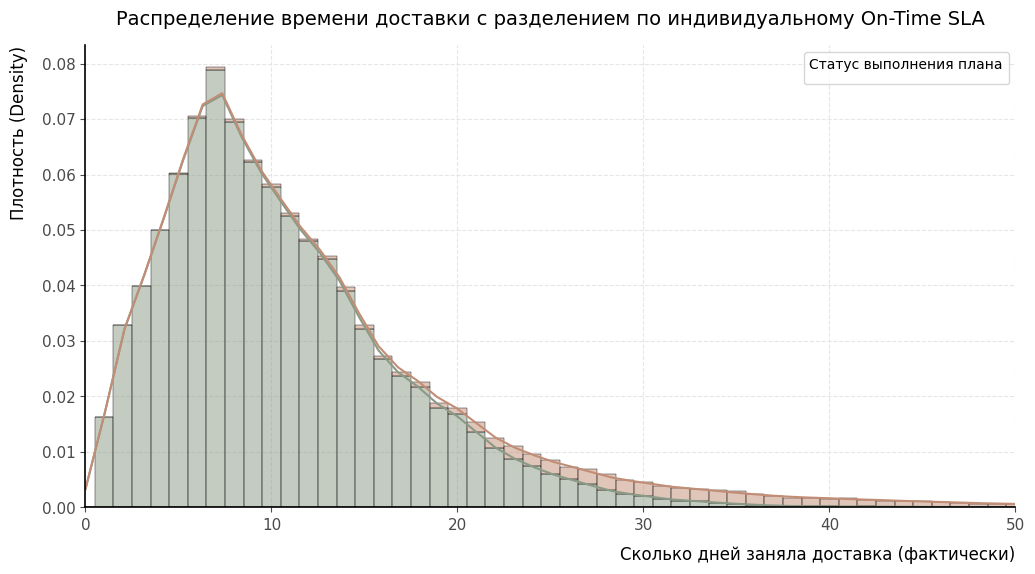

In [ ]:
# 1. Считаем индивидуальное смещение от планового срока для каждого заказа (в днях)
# Отрицательное значение = приехало раньше срока (Успех)
# Положительное значение = опоздание на X дней
delivered_orders['order_delivered_customer_date'] = pd.to_datetime(delivered_orders['order_delivered_customer_date'])
delivered_orders['order_estimated_delivery_date'] = pd.to_datetime(delivered_orders['order_estimated_delivery_date'])

delivered_orders['delta_delivery_days'] = (
    delivered_orders['order_delivered_customer_date'] - delivered_orders['order_estimated_delivery_date']
).dt.days

# 2. Создаем бинарный флаг своевременности на основе индивидуального плана
delivered_orders['delivery_on_time'] = delivered_orders['delta_delivery_days'].apply(
    lambda x: 'Вовремя / Раньше срока' if x <= 0 else 'С опозданием'
)

# 3. Настройка параметров фигуры
plt.figure(figsize=(12, 6))

olist_palette = {"Вовремя / Раньше срока": "#8A9A86", "С опозданием": "#C28D75"}

# 4. Строим распределение реального времени доставки,
# но группируем цвета по реальному выполнению дедлайна Olist
sns.histplot(
    data=delivered_orders[delivered_orders['time_of_delivery_days'] >= 0],
    x="time_of_delivery_days",
    hue="delivery_on_time",
    palette=olist_palette,
    kde=True,
    stat='density',
    discrete=True,
    multiple="stack" # Складываем бары друг на друга, чтобы видеть общую плотность
)

plt.title("Распределение времени доставки с разделением по индивидуальному On-Time SLA", fontsize=14, pad=15)
plt.xlabel("Сколько дней заняла доставка (фактически)", fontsize=12)
plt.ylabel("Плотность (Density)", fontsize=12)
plt.xlim(0, 50)
plt.legend(title="Статус выполнения плана")
plt.show()


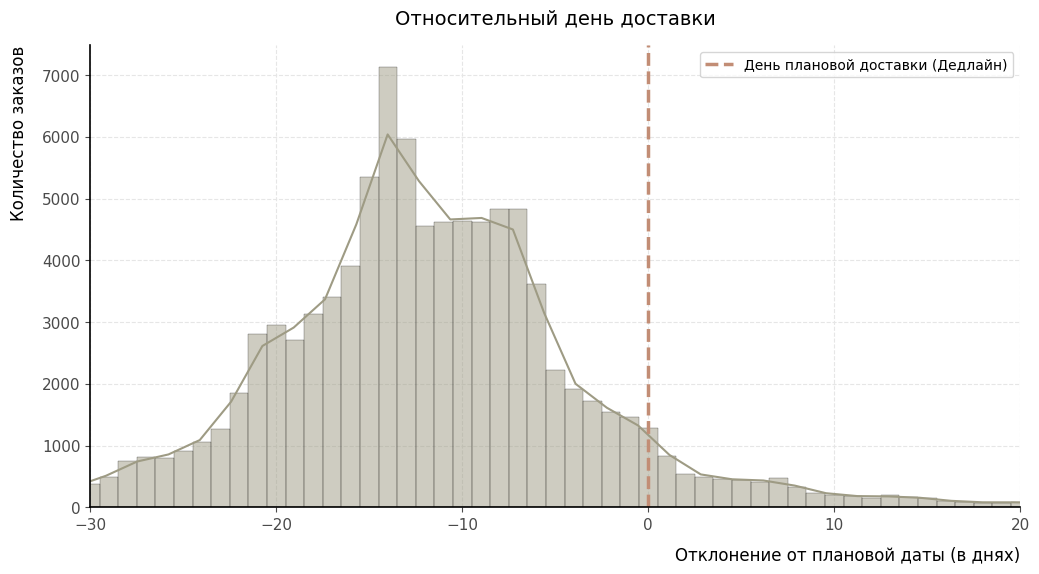

In [ ]:
plt.figure(figsize=(12, 6))

# Строим распределение дельты. Все, что левее 0 — это доставили раньше плана.
sns.histplot(
    data=delivered_orders,
    x="delta_delivery_days",
    color="#9E9B84", # Пыльный хаки
    kde=True,
    discrete=True,
    stat='count'
)

# Вертикальная черта дедлайна. Справа от неё — зона проблемных заказов.
plt.axvline(x=0, color='#C28D75', linestyle='--', linewidth=2.5, label='День плановой доставки (Дедлайн)')

plt.title("Относительный день доставки", fontsize=14, pad=15)
plt.xlabel("Отклонение от плановой даты (в днях)", fontsize=12)
plt.ylabel("Количество заказов", fontsize=12)
plt.xlim(-30, 20) # Ограничим диапазон, чтобы скрыть экстремальные выбросы
plt.legend()
plt.show()


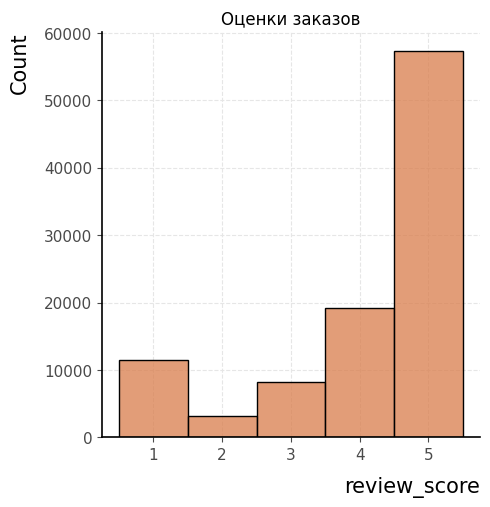

In [ ]:
sns.displot(data=reviews, x="review_score", discrete=True, color="#D97D4B")
plt.title("Оценки заказов")
plt.show()

# Анализ Marketing Funnel данных

In [ ]:

print("Загрузка датасета Marketing Funnel...")
path_hub = kagglehub.dataset_download("olistbr/marketing-funnel-olist")

destination_path = '/content/marketing_funnel'

if not os.path.exists(destination_path):
    os.makedirs(destination_path)
    print(f"Создана папка: {destination_path}")

for filename in os.listdir(path_hub):
    shutil.copy(os.path.join(path_hub, filename), os.path.join(destination_path, filename))

print(f"\nДанные успешно скопированы в: {destination_path}")
!ls {destination_path}
path2data = destination_path

Загрузка датасета Marketing Funnel...
Using Colab cache for faster access to the 'marketing-funnel-olist' dataset.

Данные успешно скопированы в: /content/marketing_funnel
olist_closed_deals_dataset.csv	olist_marketing_qualified_leads_dataset.csv


In [ ]:
closed_deals_raw = pd.read_csv(os.path.join(path2data, 'olist_closed_deals_dataset.csv'))
mql_raw = pd.read_csv(os.path.join(path2data, 'olist_marketing_qualified_leads_dataset.csv'))

In [ ]:
closed_deals = closed_deals_raw.copy()
mql = mql_raw.copy()

In [ ]:
closed_deals.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 842 entries, 0 to 841
Data columns (total 14 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   mql_id                         842 non-null    object 
 1   seller_id                      842 non-null    object 
 2   sdr_id                         842 non-null    object 
 3   sr_id                          842 non-null    object 
 4   won_date                       842 non-null    object 
 5   business_segment               841 non-null    object 
 6   lead_type                      836 non-null    object 
 7   lead_behaviour_profile         665 non-null    object 
 8   has_company                    63 non-null     object 
 9   has_gtin                       64 non-null     object 
 10  average_stock                  66 non-null     object 
 11  business_type                  832 non-null    object 
 12  declared_product_catalog_size  69 non-null     flo

In [ ]:
mql.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   mql_id              8000 non-null   object
 1   first_contact_date  8000 non-null   object
 2   landing_page_id     8000 non-null   object
 3   origin              7940 non-null   object
dtypes: object(4)
memory usage: 250.1+ KB


In [ ]:
mql.head()

,mql_id,first_contact_date,landing_page_id,origin
0,dac32acd4db4c29c230538b72f8dd87d,2018-02-01,88740e65d5d6b056e0cda098e1ea6313,social
1,8c18d1de7f67e60dbd64e3c07d7e9d5d,2017-10-20,007f9098284a86ee80ddeb25d53e0af8,paid_search
2,b4bc852d233dfefc5131f593b538befa,2018-03-22,a7982125ff7aa3b2054c6e44f9d28522,organic_search
3,6be030b81c75970747525b843c1ef4f8,2018-01-22,d45d558f0daeecf3cccdffe3c59684aa,email
4,5420aad7fec3549a85876ba1c529bd84,2018-02-21,b48ec5f3b04e9068441002a19df93c6c,organic_search


In [ ]:
mql.origin.value_counts()

,count
origin,
organic_search,2296
paid_search,1586
social,1350
unknown,1099
direct_traffic,499
email,493
referral,284
other,150
display,118


In [ ]:
mql.landing_page_id.value_counts()

,count
landing_page_id,
b76ef37428e6799c421989521c0e5077,912
22c29808c4f815213303f8933030604c,883
58326e62183c14b0c03085c33b9fdc44,495
88740e65d5d6b056e0cda098e1ea6313,445
ce1a65abd0973638f1c887a6efcfa82d,394
...,...
5215a2f4c4cb554cb18c8de3b4f06df5,1
d27094ded8d5242d4d2ba9d7e5f176b4,1
ffc62d6945fd1423539ec6d96326c37c,1


In [ ]:
mql.mql_id.nunique()

8000

In [ ]:
closed_deals.head()

,mql_id,seller_id,sdr_id,sr_id,won_date,business_segment,lead_type,lead_behaviour_profile,has_company,has_gtin,average_stock,business_type,declared_product_catalog_size,declared_monthly_revenue
0,5420aad7fec3549a85876ba1c529bd84,2c43fb513632d29b3b58df74816f1b06,a8387c01a09e99ce014107505b92388c,4ef15afb4b2723d8f3d81e51ec7afefe,2018-02-26 19:58:54,pet,online_medium,cat,NaN,NaN,NaN,reseller,NaN,0.0
1,a555fb36b9368110ede0f043dfc3b9a0,bbb7d7893a450660432ea6652310ebb7,09285259593c61296eef10c734121d5b,d3d1e91a157ea7f90548eef82f1955e3,2018-05-08 20:17:59,car_accessories,industry,eagle,NaN,NaN,NaN,reseller,NaN,0.0
2,327174d3648a2d047e8940d7d15204ca,612170e34b97004b3ba37eae81836b4c,b90f87164b5f8c2cfa5c8572834dbe3f,6565aa9ce3178a5caf6171827af3a9ba,2018-06-05 17:27:23,home_appliances,online_big,cat,NaN,NaN,NaN,reseller,NaN,0.0
3,f5fee8f7da74f4887f5bcae2bafb6dd6,21e1781e36faf92725dde4730a88ca0f,56bf83c4bb35763a51c2baab501b4c67,d3d1e91a157ea7f90548eef82f1955e3,2018-01-17 13:51:03,food_drink,online_small,NaN,NaN,NaN,NaN,reseller,NaN,0.0
4,ffe640179b554e295c167a2f6be528e0,ed8cb7b190ceb6067227478e48cf8dde,4b339f9567d060bcea4f5136b9f5949e,d3d1e91a157ea7f90548eef82f1955e3,2018-07-03 20:17:45,home_appliances,industry,wolf,NaN,NaN,NaN,manufacturer,NaN,0.0


In [ ]:
closed_deals.shape

(842, 14)

In [ ]:
closed_deals.mql_id.nunique()


842

In [ ]:
CR = closed_deals.mql_id.nunique() / mql.mql_id.nunique()
print(f"Конверсия в оформление сделки составляет CR = {CR}")

Конверсия в оформление сделки составляет CR = 0.10525


In [ ]:
closed_deals.business_segment.value_counts()

,count
business_segment,
home_decor,105
health_beauty,93
car_accessories,77
household_utilities,71
construction_tools_house_garden,69
...,...
other,3
air_conditioning,3
perfume,2


In [ ]:
closed_deals.lead_type.value_counts()

,count
lead_type,
online_medium,332
online_big,126
industry,123
offline,104
online_small,77
online_beginner,57
online_top,14
other,3


In [ ]:
closed_and_mql = pd.merge(left=closed_deals, right=mql, on="mql_id", how="left")

In [ ]:
closed_deals_by_channels = (closed_and_mql.origin.value_counts().reset_index()
.merge(mql.origin.value_counts().reset_index(), on="origin", how="right")
.rename(columns={"count_x": "closed", "count_y": "all"})
)

In [ ]:
closed_deals_by_channels

,origin,closed,all
0,organic_search,271,2296
1,paid_search,195,1586
2,social,75,1350
3,unknown,179,1099
4,direct_traffic,56,499
5,email,15,493
6,referral,24,284
7,other,4,150
8,display,6,118
9,other_publicities,3,65


In [ ]:
closed_deals_by_channels['CR'] = closed_deals_by_channels['closed'] / closed_deals_by_channels['all']
closed_deals_by_channels

,origin,closed,all,CR
0,organic_search,271,2296,0.118031
1,paid_search,195,1586,0.122951
2,social,75,1350,0.055556
3,unknown,179,1099,0.162875
4,direct_traffic,56,499,0.112224
5,email,15,493,0.030426
6,referral,24,284,0.084507
7,other,4,150,0.026667
8,display,6,118,0.050847
9,other_publicities,3,65,0.046154


In [ ]:
import numpy as np
from statsmodels.stats.weightstats import ttest_ind

# Создаем сырые массивы из 0 и 1
group_organic = np.array([1] * 271 + [0] * (2296 - 271))
group_paid = np.array([1] * 195 + [0] * (1586 - 195))

# Проверяем размеры массивов для уверенности
print(f"Длина выборки Organic: {len(group_organic)} (должна быть 2296)")
print(f"Длина выборки Paid: {len(group_paid)} (должна быть 1586)")

# Запускаем t-тест
t_stat, p_value, df = ttest_ind(group_organic, group_paid, alternative='two-sided', usevar='unequal')

print(f"\nt-статистика: {t_stat:.4f}")
print(f"p-value: {p_value:.4f}")


Длина выборки Organic: 2296 (должна быть 2296)
Длина выборки Paid: 1586 (должна быть 1586)

t-статистика: -0.4620
p-value: 0.6441


In [ ]:
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests
import pandas as pd

# 1. Извлекаем данные для базовой группы (unknown)
unknown_row = closed_deals_by_channels[closed_deals_by_channels['origin'] == 'unknown']

if unknown_row.empty:
    print("Ошибка: канал 'unknown' не найден в таблице!")
else:
    success_A = int(unknown_row['closed'].values[0])
    all_A = int(unknown_row['all'].values[0])

    raw_p_values = []
    compared_channels = []

    # 2. Проводим Z-тест со всеми остальными каналами по очереди
    for index, row in closed_deals_by_channels.iterrows():
        channel = row['origin']

        # Пропускаем сам unknown и каналы, где слишком мало данных (меньше 5 лидов)
        if channel == 'unknown' or row['all'] < 5:
            continue

        success_B = int(row['closed'])
        all_B = int(row['all'])

        # Запуск стандартного Z-теста
        _, p_val = proportions_ztest([success_A, success_B], [all_A, all_B])

        raw_p_values.append(p_val)
        compared_channels.append(channel)

    # 3. Применяем поправку на множественное тестирование (метод Холма)
    # Это защитит нас от случайных «ошибочных» открытий
    rejected, corrected_p_vals, _, _ = multipletests(raw_p_values, alpha=0.05, method='holm')

    # 4. Собираем результаты в красивую итоговую таблицу
    results_df = pd.DataFrame({
        'Channel': compared_channels,
        'Raw p-value': raw_p_values,
        'Corrected p-value': corrected_p_vals,
        'Significantly Different': rejected
    }).sort_values(by='Corrected p-value')

    print("Результаты сравнения канала 'unknown' с остальными источниками:")
    display(results_df)


Результаты сравнения канала 'unknown' с остальными источниками:


,Channel,Raw p-value,Corrected p-value,Significantly Different
2,social,4.565029e-18,4.108526e-17,True
4,email,8.052349e-14,6.441880e-13,True
6,other,9.638295e-06,6.746806e-05,True
0,organic_search,3.116078e-04,1.869647e-03,True
5,referral,8.786435e-04,4.393217e-03,True
7,display,1.277612e-03,5.110449e-03,True
1,paid_search,3.305192e-03,9.915575e-03,True
3,direct_traffic,8.064180e-03,1.612836e-02,True
8,other_publicities,1.181483e-02,1.612836e-02,True


# Гипотезы

Проверим несколько гипотез

In [ ]:
import statsmodels.api as sm
from scipy import stats

In [ ]:
payments['payment_type'].value_counts()

,count
payment_type,
credit_card,76795
boleto,19784
voucher,5775
debit_card,1529
not_defined,3


In [ ]:
 payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [ ]:
macro_regions = {
    "SP": "Southeast", "RJ": "Southeast", "MG": "Southeast", "ES": "Southeast",
    "PR": "South", "RS": "South", "SC": "South",
    "BA": "Northeast", "CE": "Northeast", "PE": "Northeast", "MA": "Northeast",
    "PB": "Northeast", "RN": "Northeast", "AL": "Northeast", "SE": "Northeast", "PI": "Northeast",
    "DF": "Central-West", "GO": "Central-West", "MT": "Central-West", "MS": "Central-West",
    "AM": "North", "PA": "North", "RO": "North", "TO": "North", "AC": "North", "AP": "North", "RR": "North",
}

# 1. Объединяем данные (платежи -> заказы -> клиенты)
df_merged = payments.merge(orders[['order_id', 'customer_id']], on='order_id')
df_geo_payments = df_merged.merge(customers[['customer_id', 'customer_state']], on='customer_id')

# 2. Фильтруем редкие/неопределенные типы оплаты, чтобы тест был максимально чистым
active_payments = df_geo_payments[df_geo_payments['payment_type'].isin(['credit_card', 'boleto', 'voucher', 'debit_card'])].copy()

# 3. Добавляем колонку с макрорегионом с помощью вашего словаря
active_payments['macro_region'] = active_payments['customer_state'].map(macro_regions)

# 4. Строим таблицу сопряженности "Макрорегион - Тип оплаты"
contingency_table = pd.crosstab(active_payments['macro_region'], active_payments['payment_type'])

print("--- Таблица сопряженности (количество транзакций) ---")
print(contingency_table)
print("\n" + "="*50 + "\n")

# Полезно также посмотреть на распределение в процентах по строкам
print("--- Таблица сопряженности (в % по регионам) ---")
print(contingency_table.div(contingency_table.sum(axis=1), axis=0) * 100)
print("\n" + "="*50 + "\n")

# 5. Запускаем критерий Хи-квадрат Пирсона
chi2, p_val, dof, expected = stats.chi2_contingency(contingency_table)

print(f"Статистика Хи-квадрат (chi2): {chi2:.4f}")
print(f"Степени свободы (dof): {dof}")
print(f"p-value: {p_val}")

# 6. Интерпретация
if p_val < 0.05:
    print("\nРезультат статистически значим: Выбор типа оплаты зависит от региона.")
    print("Структура платежей между регионами Бразилии имеет реальные, неслучайные отличия.")
else:
    print("\nРезультат незначим: регион не влияет на выбор типа оплаты.")


--- Таблица сопряженности (количество транзакций) ---
payment_type  boleto  credit_card  debit_card  voucher
macro_region                                          
Central-West    1258         4398          56      298
North            425         1376          27       99
Northeast       1709         7438         139      621
South           3317        10484         197      686
Southeast      13075        53099        1110     4071


--- Таблица сопряженности (в % по регионам) ---
payment_type     boleto  credit_card  debit_card   voucher
macro_region                                              
Central-West  20.931780    73.178037    0.931780  4.958403
North         22.055008    71.406331    1.401142  5.137519
Northeast     17.250429    75.078228    1.403048  6.268295
South         22.589213    71.397439    1.341596  4.671752
Southeast     18.323874    74.415248    1.555602  5.705276


Статистика Хи-квадрат (chi2): 226.7999
Степени свободы (dof): 12
p-value: 9.21121308890444e-42



In [ ]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [ ]:
delivered_payments.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,month,payment_sequential,payment_type,payment_installments,payment_value
0,cb29497c3782a76b57327c055d58b0e0,663c23427108785957931a3ac88f6085,delivered,2016-10-04 16:41:59,2016-10-06 15:55:55,2016-10-24 07:05:30,2016-10-29 12:53:41,2016-11-28 00:00:00,2016-10,1,credit_card,5,163.20
1,0ca768c507d1fc3c61bd950bb1c5231a,b3fb50a69d9de3ee23504d2cd66da13f,delivered,2016-10-10 15:20:14,2016-10-10 16:02:25,2016-10-30 11:23:50,2016-11-07 14:51:45,2016-12-06 00:00:00,2016-10,1,credit_card,1,112.52
2,2e8e21db96a8ab922e51cd297678c6b2,6a58b195be76f8ad6544e032b6c7316b,delivered,2016-10-09 12:13:58,2016-10-10 01:16:09,2016-10-25 13:54:41,2016-10-28 14:11:47,2016-12-02 00:00:00,2016-10,1,credit_card,1,87.29
3,25f680bf746bec3df11d48318ff015de,fd997caf29864e0b5e0d328a2d163e3f,delivered,2016-10-09 22:42:35,2016-10-10 11:02:43,2016-10-27 17:11:35,2016-11-01 18:04:41,2016-12-02 00:00:00,2016-10,2,voucher,1,12.19
4,25f680bf746bec3df11d48318ff015de,fd997caf29864e0b5e0d328a2d163e3f,delivered,2016-10-09 22:42:35,2016-10-10 11:02:43,2016-10-27 17:11:35,2016-11-01 18:04:41,2016-12-02 00:00:00,2016-10,1,voucher,1,43.43


In [ ]:
# 1. Выделяем год из колонки month
delivered_payments['purchase_year'] = delivered_payments['month'].astype(str).str[:4].astype(int)

# 2. Добавляем уникальный ID клиента (убедитесь, что имя таблицы 'customers' верное)
df_with_unique_customers = pd.merge(
    delivered_payments,
    customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='inner'
)

# 3. Выделяем клиентов 2017 года для фильтрации независимости выборок
customers_2017 = df_with_unique_customers[df_with_unique_customers['purchase_year'] == 2017]['customer_unique_id'].unique()

# 4. Считаем чистый ARPPU (сумму на юзера) по годам
arppu_2017 = (
    df_with_unique_customers[df_with_unique_customers['purchase_year'] == 2017]
    .groupby('customer_unique_id')['payment_value']
    .sum()
    .to_numpy()
)

arppu_2018 = (
    df_with_unique_customers[
        (df_with_unique_customers['purchase_year'] == 2018) &
        (~df_with_unique_customers['customer_unique_id'].isin(customers_2017))
    ]
    .groupby('customer_unique_id')['payment_value']
    .sum()
    .to_numpy()
)

# Фиксируем генератор случайных чисел для воспроизводимости
rng = np.random.default_rng(seed=42)

# --- БУТСТРАП, ОПТИМИЗИРОВАННЫЙ ПО ПАМЯТИ ---
n_resamples = 2000  # 2000 шагов более чем достаточно для точной оценки медианы
boot_diffs = []

print("Запуск бутстрапа... Пожалуйста, подождите.")
for i in range(n_resamples):
    # Генерируем случайные подвыборки С ВОЗВРАЩЕНИЕМ (размер равен исходному)
    sample_2017 = rng.choice(arppu_2017, size=len(arppu_2017), replace=True)
    sample_2018 = rng.choice(arppu_2018, size=len(arppu_2018), replace=True)

    # Считаем разницу медиан и сохраняем только результат
    diff = np.median(sample_2018) - np.median(sample_2017)
    boot_diffs.append(diff)

    # Небольшой индикатор прогресса, чтобы видеть, что Colab не завис
    if (i + 1) % 500 == 0:
        print(f"Готово итераций: {i + 1}/{n_resamples}")

# Превращаем результат в массив numpy
boot_diffs = np.array(boot_diffs)

# 5. СТРОИМ ПРОЦЕНТИЛЬНЫЙ ДОВЕРИТЕЛЬНЫЙ ИНТЕРВАЛ (Аналог Уилсона/классического процентильного)
# Для 95% интервала отсекаем 2.5% снизу и 2.5% сверху
ci_low = np.percentile(boot_diffs, 2.5)
ci_high = np.percentile(boot_diffs, 97.5)

print("\n" + "="*50)
print(f"Медиана ARPPU 2017: {np.median(arppu_2017):.2f} BRL")
print(f"Медиана ARPPU 2018: {np.median(arppu_2018):.2f} BRL")
print(f"Фактическая разница медиан: {np.median(arppu_2018) - np.median(arppu_2017):.2f} BRL")
print("-"*50)
print(f"95% Доверительный интервал для разницы медиан:")
print(f"[{ci_low:.2f}; {ci_high:.2f}] BRL")
print("="*50)

Запуск бутстрапа... Пожалуйста, подождите.
Готово итераций: 500/2000
Готово итераций: 1000/2000
Готово итераций: 1500/2000
Готово итераций: 2000/2000

Медиана ARPPU 2017: 106.08 BRL
Медиана ARPPU 2018: 108.35 BRL
Фактическая разница медиан: 2.27 BRL
--------------------------------------------------
95% Доверительный интервал для разницы медиан:
[1.10; 3.67] BRL


In [ ]:
rng = np.random.default_rng(seed=42)
n_resamples = 2000

# Словари для сохранения разниц по разным перцентилям
boot_diffs_q25 = []
boot_diffs_q50 = []
boot_diffs_q75 = []

print("Считаем квантильный бутстрап...")
for i in range(n_resamples):
    sample_2017 = rng.choice(arppu_2017, size=len(arppu_2017), replace=True)
    sample_2018 = rng.choice(arppu_2018, size=len(arppu_2018), replace=True)

    # Считаем разницы для разных слоев распределения
    boot_diffs_q25.append(np.percentile(sample_2018, 25) - np.percentile(sample_2017, 25))
    boot_diffs_q50.append(np.percentile(sample_2018, 50) - np.percentile(sample_2017, 50))
    boot_diffs_q75.append(np.percentile(sample_2018, 75) - np.percentile(sample_2017, 75))

print("\n" + "="*60)
print("95% Доверительные интервалы для изменений по сегментам:")
print(f"Эконом-сегмент (25-й квантиль): [{np.percentile(boot_diffs_q25, 2.5):.2f}; {np.percentile(boot_diffs_q25, 97.5):.2f}] BRL")
print(f"Типичный сегмент (50-й квантиль): [{np.percentile(boot_diffs_q50, 2.5):.2f}; {np.percentile(boot_diffs_q50, 97.5):.2f}] BRL")
print(f"Премиум-сегмент (75-й квантиль): [{np.percentile(boot_diffs_q75, 2.5):.2f}; {np.percentile(boot_diffs_q75, 97.5):.2f}] BRL")
print("="*60)


Считаем квантильный бутстрап...

95% Доверительные интервалы для изменений по сегментам:
Эконом-сегмент (25-й квантиль): [-0.88; 0.65] BRL
Типичный сегмент (50-й квантиль): [1.10; 3.67] BRL
Премиум-сегмент (75-й квантиль): [-2.24; 3.89] BRL


In [ ]:
# 1. ПОДГОТОВКА ДАННЫХ
# Убедимся, что даты имеют формат datetime
delivered_orders['order_purchase_timestamp'] = pd.to_datetime(delivered_orders['order_purchase_timestamp'])
delivered_orders['order_delivered_customer_date'] = pd.to_datetime(delivered_orders['order_delivered_customer_date'])
delivered_orders['order_estimated_delivery_date'] = pd.to_datetime(delivered_orders['order_estimated_delivery_date'])

# Достаем год покупки из колонки month (как на прошлых шагах)
delivered_orders['purchase_year'] = delivered_orders['month'].astype(str).str[:4].astype(int)

# Фильтруем только 2017 и 2018 года и исключаем аномалии (если доставка < 0 дней из-за ошибок в данных)
df_logistics = delivered_orders[
    (delivered_orders['purchase_year'].isin([2017, 2018])) &
    (delivered_orders['time_of_delivery_days'] >= 0)
].copy()

# Считаем флаг опоздания: 1 если привезли позже обещанного, 0 если вовремя
df_logistics['is_late'] = (df_logistics['order_delivered_customer_date'] > df_logistics['order_estimated_delivery_date']).astype(int)

# Разделяем на массивы дней доставки
days_2017 = df_logistics[df_logistics['purchase_year'] == 2017]['time_of_delivery_days'].to_numpy()
days_2018 = df_logistics[df_logistics['purchase_year'] == 2018]['time_of_delivery_days'].to_numpy()

print(f"Заказов в 2017: {len(days_2017)} | Заказов в 2018: {len(days_2018)}")
print(f"Фактическая медиана доставки 2017: {np.median(days_2017):.1f} дн. | 2018: {np.median(days_2018):.1f} дн.")
print(f"Фактический 95-й перцентиль 2017: {np.percentile(days_2017, 95):.1f} дн. | 2018: {np.percentile(days_2018, 95):.1f} дн.")
print("-"*60)


# 2. БУТСТРАП ДЛЯ МЕДИАНЫ И 95-ГО ПЕРЦЕНТИЛЯ (Безопасный для памяти Colab)
rng = np.random.default_rng(seed=42)
n_resamples = 2000

boot_diffs_median = []
boot_diffs_p95 = []

print("Запуск бутстрапа для сроков доставки...")
for i in range(n_resamples):
    sample_2017 = rng.choice(days_2017, size=len(days_2017), replace=True)
    sample_2018 = rng.choice(days_2018, size=len(days_2018), replace=True)

    # Считаем разницы (2018 - 2017)
    boot_diffs_median.append(np.median(sample_2018) - np.median(sample_2017))
    boot_diffs_p95.append(np.percentile(sample_2018, 95) - np.percentile(sample_2017, 95))

# Считаем доверительные интервалы разниц
ci_med_low, ci_med_high = np.percentile(boot_diffs_median, 2.5), np.percentile(boot_diffs_median, 97.5)
ci_p95_low, ci_p95_high = np.percentile(boot_diffs_p95, 2.5), np.percentile(boot_diffs_p95, 97.5)


# 3. Z-ТЕСТ ДЛЯ ДОЛИ ОПОЗДАНИЙ (LATE RATE)
# Для долей (конверсий) бутстрап не нужен, Z-тест пропорций работает мгновенно и идеально
late_2017 = df_logistics[df_logistics['purchase_year'] == 2017]['is_late']
late_2018 = df_logistics[df_logistics['purchase_year'] == 2018]['is_late']

count_late = np.array([late_2017.sum(), late_2018.sum()])
n_orders = np.array([len(late_2017), len(late_2018)])

# Запускаем двухвыборочный тест пропорций
z_stat, p_val_late = sm.stats.proportions_ztest(count_late, n_orders)


print("="*60)
print(f"95% ДИ изменения МЕДИАНЫ доставки: [{ci_med_low:.2f}; {ci_med_high:.2f}] дней")
print(f"95% ДИ изменения 95-го ПЕРЦЕНТИЛЯ (хвоста): [{ci_p95_low:.2f}; {ci_p95_high:.2f}] дней")
print("-"*60)
print(f"Доля опозданий в 2017: {late_2017.mean():.2%}")
print(f"Доля опозданий в 2018: {late_2018.mean():.2%}")
print(f"p-value для изменения доли опозданий: {p_val_late:.5f}")
print("="*60)


Заказов в 2017: 43426 | Заказов в 2018: 52777
Фактическая медиана доставки 2017: 11.0 дн. | 2018: 9.0 дн.
Фактический 95-й перцентиль 2017: 28.0 дн. | 2018: 29.0 дн.
------------------------------------------------------------
Запуск бутстрапа для сроков доставки...
95% ДИ изменения МЕДИАНЫ доставки: [-2.00; -1.00] дней
95% ДИ изменения 95-го ПЕРЦЕНТИЛЯ (хвоста): [1.00; 2.00] дней
------------------------------------------------------------
Доля опозданий в 2017: 6.63%
Доля опозданий в 2018: 9.37%
p-value для изменения доли опозданий: 0.00000


In [ ]:
# 1. Выделяем год покупки из готовой колонки month
delivered_orders['purchase_year'] = delivered_orders['month'].astype(str).str[:4].astype(int)

# 2. Фильтруем данные (убираем только редкие ошибки, где дни доставки получились меньше 0)
clean_delivery = delivered_orders[delivered_orders['time_of_delivery_days'] >= 0]

# 3. Выделяем сырые массивы дней доставки по годам
days_2017 = clean_delivery[clean_delivery['purchase_year'] == 2017]['time_of_delivery_days'].dropna().to_numpy()
days_2018 = clean_delivery[clean_delivery['purchase_year'] == 2018]['time_of_delivery_days'].dropna().to_numpy()

print(f"Наблюдений в 2017: {len(days_2017)} | в 2018: {len(days_2018)}")
print(f"Сырое среднее время доставки 2017: {days_2017.mean():.2f} дней")
print(f"Сырое среднее время доставки 2018: {days_2018.mean():.2f} дней")
print("-"*50)

# 4. Запускаем тест Уэлча (equal_var=False)
res = stats.ttest_ind(days_2018, days_2017, equal_var=False)  # Поменяли местами 2018 и 2017 для соответствия (2018 - 2017)

# 5. Мгновенно вытаскиваем точный аналитический доверительный интервал
# res.confidence_interval() автоматически учитывает поправку Уэлча, если указано equal_var=False
ci_low, ci_high = res.confidence_interval(confidence_level=0.95)

p_val = res.pvalue

print(f"p-value теста Уэлча: {p_val:.5f}")
print(f"95% Доверительный интервал для разницы средних сроков доставки (2018 - 2017):")
print(f"[{ci_low:.2f}; {ci_high:.2f}] дней")
print("="*50)


Наблюдений в 2017: 43426 | в 2018: 52777
Сырое среднее время доставки 2017: 12.54 дней
Сырое среднее время доставки 2018: 11.69 дней
--------------------------------------------------
p-value теста Уэлча: 0.00000
95% Доверительный интервал для разницы средних сроков доставки (2018 - 2017):
[-0.97; -0.73] дней
